# GSM Security — Interactive Teaching Laboratory

**Course:** Security of Mobile Systems  
**Format:** Guided Jupyter practical with instructor discussion and student experiments  
**Suggested duration:** 75–90 minutes (adjust to class pace)

## Learning outcomes
By the end, students should be able to (1) explain GSM subscriber authentication with Ki, RAND, and SRES; (2) distinguish subscriber authentication from network authentication; (3) describe how TMSI affects linkability; (4) explain the purpose of the A8-derived session key Kc; (5) illustrate XOR-based stream encryption; and (6) identify the assumptions behind replay, key-compromise, and keystream-reuse demonstrations.

> **Scope and safety:** All subscribers, messages, keys, and network entities are fictional. The notebook runs locally, does not contact GSM infrastructure, and does not capture real traffic. The functions `demo_A3`, `demo_A8`, and `demo_A5` use HMAC-SHA256 as **educational substitutes**; they are **not** COMP128, A5/1, or other deployed GSM algorithms. Real GSM security has additional protocol details.

**Dependencies:** Python 3, `matplotlib`, `numpy` (install with `%pip install matplotlib numpy` if needed). Run cells from top to bottom. Fresh random challenges mean hexadecimal outputs change each run.

### GSM security story
**SIM and AuC share Ki → network sends RAND → SIM returns SRES (A3) → SIM and network derive Kc (A8) → mobile and base-station-side equipment use Kc for radio-link encryption (A5).** TMSI helps avoid repeatedly revealing the permanent IMSI, but does not guarantee anonymity.


### Cryptographic Background: HMAC-SHA256

**HMAC (Hash-based Message Authentication Code)** is a cryptographic
construction that uses a secret key and a message to produce an
authentication tag.

In this experiment, we use HMAC-SHA256 as an educational substitute
for the historical GSM A3 authentication algorithm.

**Inputs:**
- Secret key (Ki): 128 bits in our experiment
- Random challenge (RAND): 128 bits

**Output:**
- HMAC-SHA256: 256 bits
- Demo SRES: First 32 bits of the HMAC output


**Security properties:**
- The same key and message produce the same output.
- Changing the key or message generally changes the output.
- Without the secret key, generating a valid tag for a new message
  should be computationally infeasible.
- HMAC provides message authentication and integrity, not encryption.

 **Security Properties**

- **Integrity:** Detects unauthorized changes to the message.
- **Authentication:** Verifies that the sender knows the secret key.
- **Confidentiality:** NOT provided. The message remains readable.
- **Replay protection:** NOT provided by HMAC alone.


**Applications:** API authentication, webhook verification,
message integrity, and certain TLS constructions.

**Connection to GSM:**

In our educational simulation:

    SRES = HMAC-SHA256(Ki, RAND)[:4]

This produces a 32-bit response, matching the size of GSM SRES.

Note: Real historical GSM A3 implementations, such as COMP128,
do not use this HMAC-SHA256 construction.


## 1. Subscriber authentication — legitimate network


# Part 1 — GSM Subscriber Authentication (A3)

## Scenario 1: Legitimate Subscriber Authentication

**Objective:** Understand how a GSM network authenticates a subscriber using a challenge-response mechanism.

### Background

In GSM, the SIM card and the mobile operator share a secret key called **Ki**.

The authentication process works as follows:

1. The network generates a random 128-bit challenge (**RAND**).
2. The network sends RAND to the mobile station.
3. The SIM uses the secret key Ki and algorithm A3 to calculate a 32-bit response (**SRES**).
4. The network independently calculates the expected SRES using the same Ki and RAND.
5. If both responses match, the subscriber is authenticated.

**Important:** The secret key Ki is never transmitted over the radio interface.



### GSM Security Limitation

GSM provides **one-way authentication**: the network authenticates the subscriber, but the SIM does not authenticate the network.

This limitation is relevant to fake base-station attacks.

### About this demonstration

We use Python's HMAC-SHA256 as an educational substitute for A3. This is **not the real GSM A3/COMP128 algorithm**, but it illustrates the challenge-response principle.

### Before running the code

Predict: What will happen if the SIM and the network use different secret keys?


SCENARIO 1: LEGITIMATE GSM SUBSCRIBER AUTHENTICATION
RAND (128 bits)       : a3b1c5c895be06ca45421f55b6c26943
SIM SRES (32 bits)    : df250446
Expected SRES        : df250446
------------------------------------------------------------
RESULT: Subscriber authentication SUCCESSFUL
Network authenticated by SIM: NO


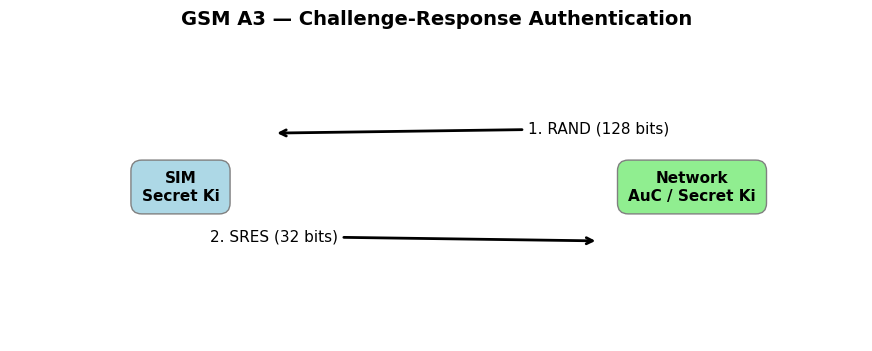

In [ ]:

# ============================================================
# GSM SECURITY LAB — PART 1
# Scenario 1: Legitimate GSM Subscriber Authentication (A3)
#
# Compatible with Google Colab and JupyterLab
# ============================================================

# STEP 1 — Import the required Python libraries

import sys
import subprocess
import importlib.util
import secrets                  # Generate secure random challenges
import hmac                     # Calculate and compare authentication responses
import hashlib                  # Provide the SHA-256 hash function
#How does secrets generate random values? The secrets library uses the operating system's cryptographically secure random number generator (CSPRNG).
#The operating system collects entropy from various system sources and uses a secure algorithm to generate unpredictable values.
#´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´#
# Install Matplotlib only if it is not already available.
# This works in both Google Colab and JupyterLab.
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "matplotlib"
    ])

import matplotlib.pyplot as plt  # Create the authentication diagram

#´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´#
# STEP 2 — Define an educational version of GSM A3

def demo_A3(key, rand):
    """
    Simulate the GSM A3 authentication function.

    Parameters:
        key  : Subscriber's secret key Ki (16 bytes)
        rand : Network challenge RAND (16 bytes)

    Returns:
        SRES : Authentication response (4 bytes = 32 bits)

    IMPORTANT:
        This function uses HMAC-SHA256 as an educational
        substitute. It does NOT implement real GSM A3/COMP128.
    """

    # Create the HMAC object using the key and RAND.
    hmac_object = hmac.new(key, rand, hashlib.sha256)#hashlib.sha256: The hash algorithm HMAC will use

    # Calculate the complete 256-bit result.
    full_result = hmac_object.digest()

    # Extract the first 4 bytes (32 bits).[:4] Python slicing selects bytes at positions 0, 1, 2, and 3. 4 bytes = 32 bits
    sres = full_result[:4]

    # Return the authentication response.
    return sres


# STEP 3 — Define the subscriber's secret key (Ki)

# In GSM, Ki is stored in the SIM and the operator's AuC.
# The secret key is never transmitted over the radio interface.
Ki_SIM = bytes.fromhex("00112233445566778899AABBCCDDEEFF")

# The network has the same subscriber-specific secret key.
Ki_NETWORK = Ki_SIM


# STEP 4 — Generate the network's random challenge (RAND)

# Generate 16 random bytes (128 bits).
# A new RAND is generated for this authentication attempt.
RAND = secrets.token_bytes(16)


# STEP 5 — SIM calculates its response (SRES)

# The SIM applies A3 using Ki and the received RAND.
sim_sres = demo_A3(Ki_SIM, RAND)


# STEP 6 — Network calculates the expected SRES

# The network's expected response is calculated using
# the same RAND and its copy of the subscriber's Ki.
network_sres = demo_A3(Ki_NETWORK, RAND)


# STEP 7 — Verify the subscriber's identity

# Compare both responses.
# If they match, subscriber authentication succeeds.
authenticated = hmac.compare_digest(sim_sres, network_sres)


# STEP 8 — Display the authentication results

print("=" * 60)
print("SCENARIO 1: LEGITIMATE GSM SUBSCRIBER AUTHENTICATION")
print("=" * 60)

print(f"RAND (128 bits)       : {RAND.hex()}")
print(f"SIM SRES (32 bits)    : {sim_sres.hex()}")
print(f"Expected SRES        : {network_sres.hex()}")

print("-" * 60)

if authenticated:
    print("RESULT: Subscriber authentication SUCCESSFUL")
else:
    print("RESULT: Subscriber authentication FAILED")

print("Network authenticated by SIM: NO")
print("=" * 60)

#´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´
# STEP 9 — Visualize the challenge-response exchange
#´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´
# Create a figure and drawing area.
fig, ax = plt.subplots(figsize=(11, 4))

# Define the coordinate system.
ax.set_xlim(0, 10)
ax.set_ylim(0, 4)

# Hide axes because this is a protocol diagram.
ax.axis("off")


# Reusable function for drawing GSM components.
def draw_node(ax, x, y, label, color):
    """
    Draw a labeled network component in the diagram.
    """
    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.7",
            facecolor=color,
            edgecolor="gray"
        )
    )


# Draw the SIM and the network.
draw_node(ax, 2, 2, "SIM\nSecret Ki", "lightblue")
draw_node(ax, 8, 2, "Network\nAuC / Secret Ki", "lightgreen")


# Draw RAND: Network -> SIM
ax.annotate(
    "1. RAND (128 bits)",
    xy=(3.1, 2.7),
    xytext=(6.9, 2.7),
    arrowprops=dict(arrowstyle="->", lw=2),
    ha="center",
    fontsize=11
)


# Draw SRES: SIM -> Network
ax.annotate(
    "2. SRES (32 bits)",
    xy=(6.9, 1.3),
    xytext=(3.1, 1.3),
    arrowprops=dict(arrowstyle="->", lw=2),
    ha="center",
    fontsize=11
)


# Add the diagram title.
ax.set_title(
    "GSM A3 — Challenge-Response Authentication",
    fontsize=14,
    fontweight="bold"
)

# Display the diagram.
plt.show()
result = hashlib.sha256(b"Hello")


**Instructor checkpoint:** Emphasize that a valid SRES authenticates the *subscriber to the network*, not the network to the SIM.

In [ ]:

import secrets
import hmac
import hashlib
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Educational A3 substitute
def demo_A3(key, rand):
    return hmac.new(
        key, rand, hashlib.sha256
    ).digest()[:4]

# One fixed challenge during the demonstration
RAND = secrets.token_bytes(16)

# Editable keys
sim_input = widgets.Text(
    value="00112233445566778899AABBCCDDEEFF",
    description="SIM Ki:",
    layout=widgets.Layout(width="520px"),
    style={"description_width": "90px"}
)

network_input = widgets.Text(
    value="00112233445566778899AABBCCDDEEFF",
    description="Network Ki:",
    layout=widgets.Layout(width="520px"),
    style={"description_width": "90px"}
)

check_button = widgets.Button(
    description="Authenticate",
    button_style="primary",
    icon="check"
)

reset_button = widgets.Button(
    description="Reset keys",
    icon="refresh"
)

new_rand_button = widgets.Button(
    description="New RAND",
    icon="random"
)

output = widgets.Output()

def authenticate(button=None):
    with output:
        clear_output(wait=True)

        try:
            sim_key = bytes.fromhex(sim_input.value)
            network_key = bytes.fromhex(network_input.value)

            if len(sim_key) != 16 or len(network_key) != 16:
                raise ValueError(
                    "Each Ki must contain exactly 16 bytes "
                    "(32 hexadecimal characters)."
                )

            sim_sres = demo_A3(sim_key, RAND)
            network_sres = demo_A3(network_key, RAND)

            valid = hmac.compare_digest(
                sim_sres, network_sres
            )

            print("RAND:        ", RAND.hex())
            print("SIM Ki:      ", sim_key.hex())
            print("Network Ki:  ", network_key.hex())
            print("-" * 50)
            print("SIM SRES:    ", sim_sres.hex())
            print("Expected:    ", network_sres.hex())

            if valid:
                display(HTML(
                    "<h2 style='color:green'>"
                    "✓ AUTHENTICATION SUCCESSFUL</h2>"
                ))
            else:
                display(HTML(
                    "<h2 style='color:red'>"
                    "✗ AUTHENTICATION FAILED</h2>"
                ))

        except ValueError as error:
            print("Invalid key:", error)

def reset_keys(button):
    original = "00112233445566778899AABBCCDDEEFF"
    sim_input.value = original
    network_input.value = original
    authenticate()

def generate_new_rand(button):
    global RAND
    RAND = secrets.token_bytes(16)
    authenticate()

check_button.on_click(authenticate)
reset_button.on_click(reset_keys)
new_rand_button.on_click(generate_new_rand)

display(widgets.VBox([
    widgets.HTML("<h3>GSM A3 — Live Authentication Lab</h3>"),
    sim_input,
    network_input,
    widgets.HBox([
        check_button, reset_button, new_rand_button
    ]),
    output
]))

authenticate()



## Part 2 — Replay Attack: Why Fresh RAND Matters

### Learning Objectives

By the end of this experiment, students should be able to:

- Explain how a replay attack works.
- Understand why GSM uses a random challenge (RAND).
- Distinguish a fresh challenge from a reused challenge.
- Explain why knowing an old SRES does not normally allow
  an attacker to authenticate with a new RAND.

### Scenario: An Attacker Records an Authentication Response

In GSM, the SIM and the operator share a secret key, Ki.

The network sends a 128-bit random challenge (RAND), and
the SIM calculates a 32-bit response (SRES).

An attacker can observe the authentication exchange and
record the transmitted SRES, but does not know Ki.

We investigate four cases:

| Case | Description | Expected result |
|---|---|---|
| 1 | Legitimate SIM responds to RAND1 | Accepted |
| 2 | Attacker replays SRES1 for fresh RAND2 | Rejected |
| 3 | Legitimate SIM responds to RAND2 | Accepted |
| 4 | Network mistakenly reuses RAND1 | Old SRES1 accepted |

### Important Security Concept: Freshness

A fresh random challenge makes a previously recorded
authentication response normally unusable.

However, if the network reuses a previous RAND, the
corresponding old SRES may become valid again.

The fourth case deliberately simulates an insecure network
implementation. It is not the expected behavior of a
properly operating GSM authentication system.

### Connection to Cryptography

We continue using our educational A3 function:

    SRES = HMAC-SHA256(Ki, RAND)[:4]

This is not the historical GSM COMP128 implementation.

### Before Running

Predict:

1. Can an attacker calculate SRES2 without knowing Ki?
2. Why should RAND change between authentication attempts?
3. What happens if the network repeats RAND1?


=== 1. LEGITIMATE AUTHENTICATION ===
RAND1: 52c8fff99b28eae100ea4fd8bcea28df
SRES1: 9a87f465
Authenticated: True
Attacker records SRES1: 9a87f465

=== 2. ATTACKER REPLAY ===
RAND2: 4397b482954b79177d33c5e2e8b5bfd9
Expected SRES2: 5f47581e
Attacker sends: 9a87f465
Fresh RAND accepted: False
Reused RAND accepted: True


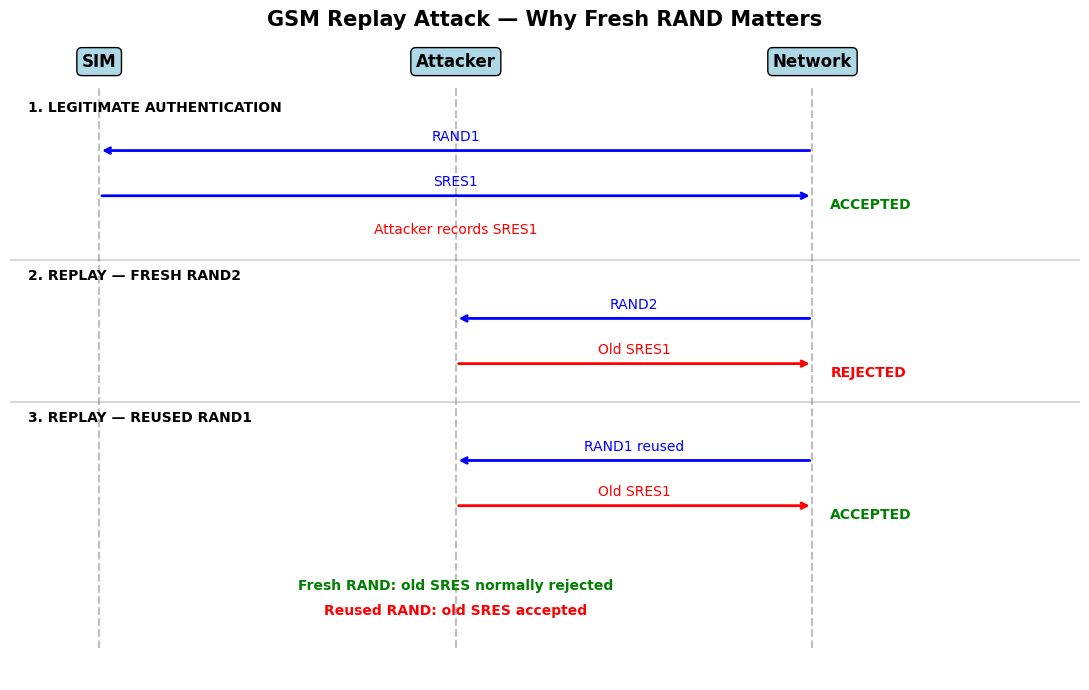

In [ ]:

# ============================================================
# GSM SECURITY LAB — REPLAY ATTACK (ONE CELL)
# Educational A3 using HMAC-SHA256, not real GSM A3
# ============================================================

import secrets
import hmac
import hashlib
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. LEGITIMATE AUTHENTICATION
# ------------------------------------------------------------

def A3(key, rand):
    # Return a 32-bit SRES (4 bytes)
    return hmac.new(key, rand, hashlib.sha256).digest()[:4]

# Shared secret between SIM and network (128 bits)
Ki = bytes.fromhex("00112233445566778899AABBCCDDEEFF")

# Network generates RAND1 (128 bits)
RAND1 = secrets.token_bytes(16)

# SIM calculates its authentication response
SRES1 = A3(Ki, RAND1)

# Network verifies the response
legitimate_ok = hmac.compare_digest(SRES1, A3(Ki, RAND1))

# Attacker intercepts and records SRES1
recorded_SRES = SRES1

print("=== 1. LEGITIMATE AUTHENTICATION ===")
print("RAND1:", RAND1.hex())
print("SRES1:", SRES1.hex())
print("Authenticated:", legitimate_ok)
print("Attacker records SRES1:", recorded_SRES.hex())


# ------------------------------------------------------------
# 2. ATTACKER REPLAY
# ------------------------------------------------------------

# CASE A: Network sends a fresh RAND2
RAND2 = secrets.token_bytes(16)
while RAND2 == RAND1:
    RAND2 = secrets.token_bytes(16)

# Attacker replays old SRES1 instead of calculating SRES2
expected_SRES2 = A3(Ki, RAND2)
fresh_ok = hmac.compare_digest(recorded_SRES, expected_SRES2)

# CASE B: Vulnerable network reuses RAND1
expected_SRES1 = A3(Ki, RAND1)
reuse_ok = hmac.compare_digest(recorded_SRES, expected_SRES1)

print("\n=== 2. ATTACKER REPLAY ===")
print("RAND2:", RAND2.hex())
print("Expected SRES2:", expected_SRES2.hex())
print("Attacker sends:", recorded_SRES.hex())
print("Fresh RAND accepted:", fresh_ok)
print("Reused RAND accepted:", reuse_ok)


# ------------------------------------------------------------
# 3. COMMUNICATION SEQUENCE DIAGRAM
#######################################################################
# Diagram
########################################################################
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

positions = {"SIM": 1, "Attacker": 5, "Network": 9}

# Draw participants and lifelines
for name, x in positions.items():
    ax.text(x, 9.5, name, ha="center",
            fontsize=12, fontweight="bold",
            bbox=dict(boxstyle="round", facecolor="lightblue"))

    ax.plot([x, x], [0.5, 9.2],
            "--", color="gray", alpha=0.5)

# Draw message arrows
def arrow(sender, receiver, y, label, color="blue"):
    x1 = positions[sender]
    x2 = positions[receiver]

    ax.annotate(
        "", xy=(x2, y), xytext=(x1, y),
        arrowprops=dict(arrowstyle="->", color=color, lw=2)
    )

    ax.text((x1 + x2) / 2, y + 0.15,
            label, ha="center", fontsize=10, color=color)


# SCENARIO 1: Legitimate authentication
ax.text(0.2, 8.8, "1. LEGITIMATE AUTHENTICATION",
        fontweight="bold")

arrow("Network", "SIM", 8.2, "RAND1")
arrow("SIM", "Network", 7.5, "SRES1")

ax.text(9.2, 7.3, "ACCEPTED", color="green", fontweight="bold")
ax.text(5, 6.9, "Attacker records SRES1",
        ha="center", color="red")


# SCENARIO 2: Replay with fresh RAND
ax.axhline(6.5, color="gray", alpha=0.3)
ax.text(0.2, 6.2, "2. REPLAY — FRESH RAND2",
        fontweight="bold")

arrow("Network", "Attacker", 5.6, "RAND2")
arrow("Attacker", "Network", 4.9, "Old SRES1", "red")

ax.text(9.2, 4.7,
        "ACCEPTED" if fresh_ok else "REJECTED",
        color="green" if fresh_ok else "red",
        fontweight="bold")


# SCENARIO 3: Replay with reused RAND
ax.axhline(4.3, color="gray", alpha=0.3)
ax.text(0.2, 4.0, "3. REPLAY — REUSED RAND1",
        fontweight="bold")

arrow("Network", "Attacker", 3.4, "RAND1 reused")
arrow("Attacker", "Network", 2.7, "Old SRES1", "red")

ax.text(9.2, 2.5,
        "ACCEPTED" if reuse_ok else "REJECTED",
        color="green" if reuse_ok else "red",
        fontweight="bold")

# Security conclusion
ax.text(5, 1.4,
        "Fresh RAND: old SRES normally rejected",
        ha="center", color="green", fontweight="bold")

ax.text(5, 1.0,
        "Reused RAND: old SRES accepted",
        ha="center", color="red", fontweight="bold")

ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

plt.title("GSM Replay Attack — Why Fresh RAND Matters",
          fontsize=15, fontweight="bold")

plt.tight_layout()
plt.show()



## Part 3 — Fake Base Station: Missing Network Authentication

### Learning Objectives

After completing this experiment, students should be able to:

1. Explain the difference between subscriber authentication
   and network authentication.
2. Identify why original GSM is vulnerable to network impersonation.
3. Explain why knowing Ki is not necessary to broadcast a
   claimed network identity.
4. Distinguish a conceptual security weakness from a real
   radio-based attack.

### Background: One-Way Authentication

In original GSM, authentication is asymmetric.

**Subscriber authentication:**
- The network challenges the SIM using RAND.
- The SIM calculates SRES using Ki.
- The network verifies SRES.

**Network authentication:**
- The SIM does not receive a cryptographic proof of
  the GSM network's identity.
- Consequently, the SIM cannot verify a base station's
  legitimacy through mutual authentication.

### Experiment

We compare three conceptual situations:

| Scenario | Network claim | Cryptographic verification |
|---|---|---|
| 1 | Legitimate GSM network | No network-authentication check |
| 2 | Fake base station | No network-authentication check |
| 3 | Hypothetical mutually authenticated network | Invalid proof rejected |

The third scenario illustrates how a cryptographic
network-authentication check could change the outcome.
It is NOT a feature of original GSM.

### Important Limitations

This experiment does not transmit radio signals, create a
real base station, force a handset to connect, or extract Ki.

It demonstrates only the missing network-authentication
security property.

### Questions

1. Why is authenticating the SIM insufficient?
2. Can a claimed network identity prove legitimacy?
3. Does a fake base station automatically know Ki?
4. What additional security property is needed to
   authenticate both parties?


GSM SECURITY — FAKE BASE STATION

LEGITIMATE NETWORK
Claimed identity: Operator A

FAKE BASE STATION
Claimed identity: Operator A

Both stations can present the same identity claim.
A matching identity claim does not prove authenticity.

SCENARIO 1 — ORIGINAL GSM
Legitimate network verification: None
Fake network verification:       None
None means NO CRYPTOGRAPHIC VERDICT.
It does not mean a connection was accepted.

SCENARIO 2 — HYPOTHETICAL NETWORK AUTHENTICATION
Legitimate network verified: True
Fake network verified:       False

IMPORTANT:
This HMAC challenge-response mechanism is
a teaching illustration, NOT original GSM.


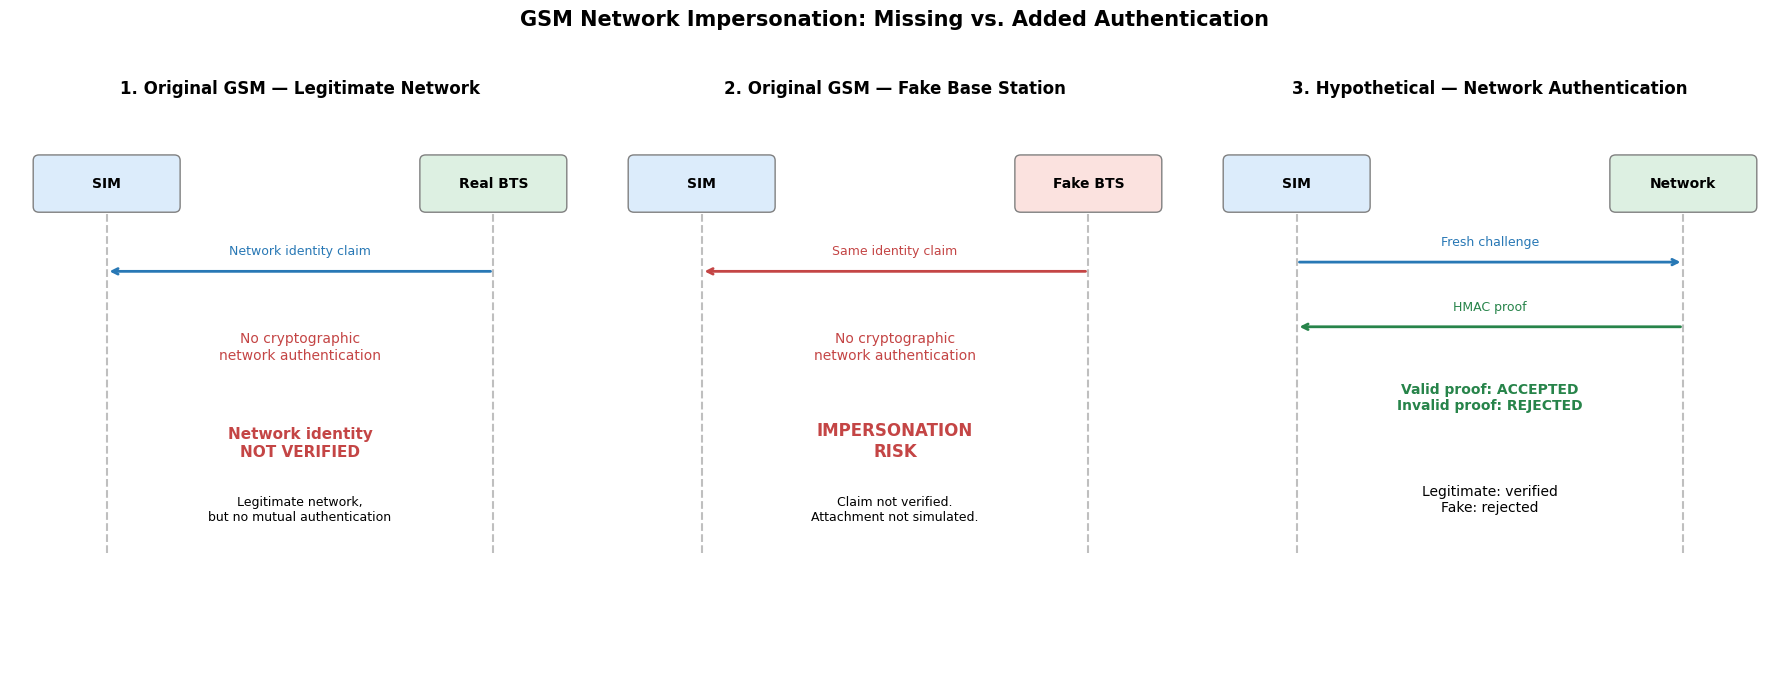

In [ ]:

# ============================================================
# GSM SECURITY LAB — PART 3
# Fake Base Station: Missing Network Authentication
#
# Conceptual simulation only:
# No radio transmissions, real base stations, or handset access.
#
# Compatible with Google Colab and JupyterLab
# ============================================================

import hmac
import hashlib
import secrets
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch


# ============================================================
# STEP 1 — REPRESENT NETWORK IDENTITY CLAIMS
# ============================================================

# A network identity claim is public information.
# A name or identifier alone is NOT cryptographic proof.

legitimate_claim = "Operator A"
fake_claim = "Operator A"

print("=" * 65)
print("GSM SECURITY — FAKE BASE STATION")
print("=" * 65)

print("\nLEGITIMATE NETWORK")
print("Claimed identity:", legitimate_claim)

print("\nFAKE BASE STATION")
print("Claimed identity:", fake_claim)

print("\nBoth stations can present the same identity claim.")
print("A matching identity claim does not prove authenticity.")


# ============================================================
# STEP 2 — MODEL ORIGINAL GSM NETWORK AUTHENTICATION
# ============================================================

def original_gsm_network_check(claimed_identity):
    """
    Illustrate the absence of cryptographic network
    authentication in original GSM.

    This is NOT a handset attachment decision.

    Return None because GSM provides no network-authentication
    verdict to the SIM.
    """

    return None


# Ask whether the SIM can cryptographically verify each claim.
legitimate_verdict = original_gsm_network_check(
    legitimate_claim
)

fake_verdict = original_gsm_network_check(
    fake_claim
)

print("\n" + "=" * 65)
print("SCENARIO 1 — ORIGINAL GSM")
print("=" * 65)

print("Legitimate network verification:", legitimate_verdict)
print("Fake network verification:      ", fake_verdict)
print("None means NO CRYPTOGRAPHIC VERDICT.")
print("It does not mean a connection was accepted.")


# ============================================================
# ''''''''''''''''''''''''''''''''''''''''''scenario3´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´#
#STEP 3 — HYPOTHETICAL MUTUAL AUTHENTICATION
# ============================================================

# This section is NOT original GSM.
# It illustrates a possible cryptographic defense.

# A trusted network and the SIM share a separate demonstration
# key for verifying network-originated authentication tags.
#
# In a real protocol, network authentication may instead use
# other cryptographic constructions and key hierarchies.

network_auth_key = secrets.token_bytes(32)

# A fake station does not know the trusted network's key.
attacker_key = secrets.token_bytes(32)

# The SIM generates a fresh challenge for the demonstration.
challenge = secrets.token_bytes(16)


def create_network_proof(key, challenge):
    """
    Calculate a demonstration network-authentication tag.

    HMAC binds the proof to the challenge and the key.
    """
    return hmac.new(
        key,
        b"NETWORK-AUTH" + challenge,
        hashlib.sha256
    ).digest()


# The legitimate network creates a proof using its key.
legitimate_proof = create_network_proof(
    network_auth_key,
    challenge
)

# The fake network tries to create a proof with a wrong key.
fake_proof = create_network_proof(
    attacker_key,
    challenge
)

# The SIM independently calculates the expected proof.
expected_proof = create_network_proof(
    network_auth_key,
    challenge
)

# Verify both proofs using constant-time comparison.
legitimate_verified = hmac.compare_digest(
    legitimate_proof,
    expected_proof
)

fake_verified = hmac.compare_digest(
    fake_proof,
    expected_proof
)

print("\n" + "=" * 65)
print("SCENARIO 2 — HYPOTHETICAL NETWORK AUTHENTICATION")
print("=" * 65)

print("Legitimate network verified:", legitimate_verified)
print("Fake network verified:      ", fake_verified)

print("\nIMPORTANT:")
print("This HMAC challenge-response mechanism is")
print("a teaching illustration, NOT original GSM.")


# ============================================================
# STEP 4 — DRAW COMMUNICATION SEQUENCE DIAGRAMS
# ============================================================

# Use three panels to make the comparison easy to follow.
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6.5)
)

BLUE = "#2878B5"
RED = "#C44545"
GREEN = "#27844A"


def participant(ax, x, label, color):
    """Draw a participant and its dashed lifeline."""

    box = FancyBboxPatch(
        (x - 0.7, 4.95),
        1.4, 0.5,
        boxstyle="round,pad=0.06",
        facecolor=color,
        edgecolor="gray"
    )
    ax.add_patch(box)

    ax.text(
        x, 5.2, label,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

    ax.plot(
        [x, x],
        [1.2, 4.9],
        "--",
        color="gray",
        alpha=0.5
    )


def message(ax, x1, x2, y, label, color):
    """Draw a labeled message arrow."""

    ax.annotate(
        "",
        xy=(x2, y),
        xytext=(x1, y),
        arrowprops=dict(
            arrowstyle="->",
            color=color,
            lw=2
        )
    )

    ax.text(
        (x1 + x2) / 2,
        y + 0.18,
        label,
        ha="center",
        fontsize=9,
        color=color
    )


def setup(ax, title):
    """Configure a panel without numerical axes."""

    ax.set_xlim(0, 6)
    ax.set_ylim(0, 6)
    ax.axis("off")
    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold",
        pad=12
    )


# ------------------------------------------------------------
# PANEL 1 — LEGITIMATE GSM NETWORK
# ------------------------------------------------------------

ax = axes[0]
setup(ax, "1. Original GSM — Legitimate Network")

participant(ax, 1, "SIM", "#DCECFB")
participant(ax, 5, "Real BTS", "#DDF0E2")

# The legitimate network presents an identity claim.
message(
    ax, 5, 1, 4.25,
    "Network identity claim",
    BLUE
)

ax.text(
    3, 3.3,
    "No cryptographic\nnetwork authentication",
    ha="center",
    fontsize=10,
    color=RED
)

ax.text(
    3, 2.25,
    "Network identity\nNOT VERIFIED",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color=RED
)

ax.text(
    3, 1.55,
    "Legitimate network,\nbut no mutual authentication",
    ha="center",
    fontsize=9
)


# ------------------------------------------------------------
# PANEL 2 — FAKE GSM BASE STATION
# ------------------------------------------------------------

ax = axes[1]
setup(ax, "2. Original GSM — Fake Base Station")

participant(ax, 1, "SIM", "#DCECFB")
participant(ax, 5, "Fake BTS", "#FBE2DF")

# The attacker claims the same network identity.
message(
    ax, 5, 1, 4.25,
    "Same identity claim",
    RED
)

ax.text(
    3, 3.3,
    "No cryptographic\nnetwork authentication",
    ha="center",
    fontsize=10,
    color=RED
)

ax.text(
    3, 2.25,
    "IMPERSONATION\nRISK",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color=RED
)

ax.text(
    3, 1.55,
    "Claim not verified.\nAttachment not simulated.",
    ha="center",
    fontsize=9
)


# ------------------------------------------------------------
# PANEL 3 — HYPOTHETICAL MUTUAL AUTHENTICATION
# ------------------------------------------------------------

ax = axes[2]
setup(ax, "3. Hypothetical — Network Authentication")

participant(ax, 1, "SIM", "#DCECFB")
participant(ax, 5, "Network", "#DDF0E2")

# The SIM sends a challenge to the network.
message(
    ax, 1, 5, 4.35,
    "Fresh challenge",
    BLUE
)

# The network responds with a cryptographic proof.
message(
    ax, 5, 1, 3.65,
    "HMAC proof",
    GREEN
)

ax.text(
    3, 2.75,
    "Valid proof: ACCEPTED\nInvalid proof: REJECTED",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color=GREEN
)

ax.text(
    3, 1.65,
    "Legitimate: verified\nFake: rejected",
    ha="center",
    fontsize=10
)

plt.suptitle(
    "GSM Network Impersonation: Missing vs. Added Authentication",
    fontsize=15,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.show()



## Part 4 — GSM A8: Session Key Generation

### Learning Objectives

After this experiment, students should be able to:

- Explain the purpose of the GSM A8 algorithm.
- Identify the inputs and output of A8.
- Understand how the SIM and home network derive the same key.
- Explain why RAND can be public while Ki must remain secret.
- Understand how Kc is subsequently used for GSM encryption.

### Background

GSM uses two related security functions:

**A3 — Subscriber Authentication**
- Inputs: Ki and RAND
- Output: SRES (32 bits)
- Purpose: Authenticate the subscriber.

**A8 — Session Key Generation**
- Inputs: Ki and RAND
- Output: Kc (64 bits)
- Purpose: Generate the ciphering key for the GSM radio link.

The SIM and the home network's Authentication Centre (AuC)
possess the same long-term secret Ki.

When both process the same RAND using the same A8 function,
they derive the same Kc independently.

The home network provides the generated Kc to the serving
network through the GSM authentication infrastructure.

The secret Ki does not need to be transmitted to the
serving network.

### Experiment

We investigate three questions:

1. Do the SIM and network derive the same Kc?
2. What happens when RAND changes?
3. What happens when the secret Ki changes?

### Important Technical Note

This notebook uses HMAC-SHA256 truncated to 64 bits as an
educational substitute for A8.

It is NOT the historical GSM COMP128 algorithm.

### Discussion Questions

1. Why can RAND be transmitted openly?
2. Why must Ki remain secret?
3. Does changing RAND change Kc?
4. What happens if the SIM and network use different Ki values?
5. What is the relationship between A8 and A5?


GSM A8 — SESSION KEY GENERATION

RAND: f1d1a4e0538b4b19ac5464d74ac647b2

SIM Kc:     4ed73e5b5f4eb5e1
Network Kc: 4ed73e5b5f4eb5e1

Keys match: True
Key length: 64 bits

SECURITY CONCLUSION
Same Ki + same RAND -> same Kc.
Different RAND -> normally different Kc.
Different Ki -> normally different Kc.
Ki must remain secret; RAND does not.


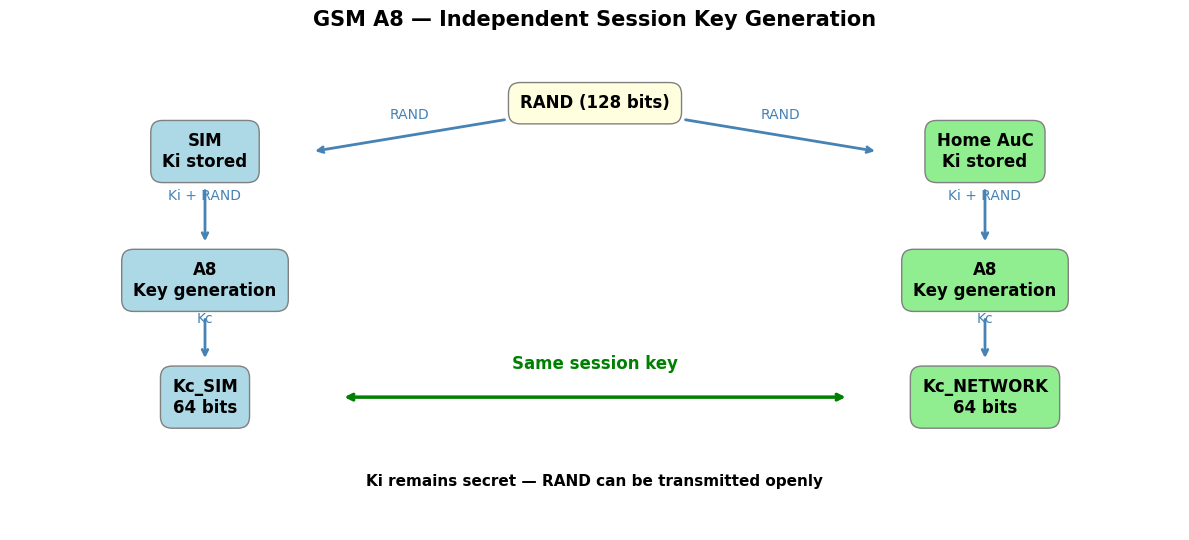

In [ ]:

# ============================================================
# GSM SECURITY LAB — PART 4
# A8: SESSION KEY GENERATION
# ============================================================

import secrets
import hmac
import hashlib


# STEP 1 — Define our educational A8 function.
def demo_A8(key, rand):

    # HMAC-SHA256 produces 32 bytes (256 bits).
    # We keep 8 bytes to simulate GSM's 64-bit Kc.
    return hmac.new(
        key,
        b"GSM-DEMO-A8" + rand,
        hashlib.sha256
    ).digest()[:8]


# STEP 2 — SIM and home network share the same Ki.
Ki_SIM = bytes.fromhex(
    "00112233445566778899AABBCCDDEEFF"
)

Ki_NETWORK = Ki_SIM


# STEP 3 — Generate a random 128-bit challenge.
RAND = secrets.token_bytes(16)


# STEP 4 — Both independently derive the session key.
Kc_SIM = demo_A8(Ki_SIM, RAND)

Kc_NETWORK = demo_A8(Ki_NETWORK, RAND)

# Preserve Kc for the next A5 encryption experiment.
Kc_A8_ORIGINAL = Kc_SIM


print("=" * 55)
print("GSM A8 — SESSION KEY GENERATION")
print("=" * 55)

print("\nRAND:", RAND.hex())

print("\nSIM Kc:    ", Kc_SIM.hex())
print("Network Kc:", Kc_NETWORK.hex())

# Verify that both sides derived the same key.
keys_match = hmac.compare_digest(Kc_SIM, Kc_NETWORK)

print("\nKeys match:", keys_match)
print("Key length:", len(Kc_SIM) * 8, "bits")



print("\nSECURITY CONCLUSION")
print("Same Ki + same RAND -> same Kc.")
print("Different RAND -> normally different Kc.")
print("Different Ki -> normally different Kc.")
print("Ki must remain secret; RAND does not.")


######################################################################################################################################################

# CELL 3 — A8 SESSION KEY GENERATION DIAGRAM
# Run after Cell 2.
# ============================================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5.5))

ax.set_xlim(0, 12)
ax.set_ylim(0, 6)
ax.axis("off")


# Draw a labeled component.
def draw_box(x, y, label, color):
    ax.text(
        x, y, label,
        ha="center", va="center",
        fontsize=12,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.7",
            facecolor=color,
            edgecolor="gray"
        )
    )


# Draw a communication or processing arrow.
def draw_arrow(x1, y1, x2, y2, label, color):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            color=color,
            lw=2
        )
    )

    ax.text(
        (x1 + x2) / 2,
        (y1 + y2) / 2 + 0.2,
        label,
        ha="center",
        fontsize=10,
        color=color
    )


# SIM and home-network authentication infrastructure.
draw_box(2, 4.7, "SIM\nKi stored", "lightblue")
draw_box(10, 4.7, "Home AuC\nKi stored", "lightgreen")

# Both sides receive the same RAND.
draw_box(6, 5.3, "RAND (128 bits)", "lightyellow")

draw_arrow(5.1, 5.1, 3.1, 4.7, "RAND", "steelblue")
draw_arrow(6.9, 5.1, 8.9, 4.7, "RAND", "steelblue")

# Independent A8 computations.
draw_box(2, 3.1, "A8\nKey generation", "lightblue")
draw_box(10, 3.1, "A8\nKey generation", "lightgreen")

draw_arrow(2, 4.25, 2, 3.55, "Ki + RAND", "steelblue")
draw_arrow(10, 4.25, 10, 3.55, "Ki + RAND", "steelblue")

# Derived session keys.
draw_box(2, 1.65, "Kc_SIM\n64 bits", "lightblue")
draw_box(10, 1.65, "Kc_NETWORK\n64 bits", "lightgreen")

draw_arrow(2, 2.65, 2, 2.1, "Kc", "steelblue")
draw_arrow(10, 2.65, 10, 2.1, "Kc", "steelblue")

# Compare the derived keys.
ax.annotate(
    "",
    xy=(8.6, 1.65),
    xytext=(3.4, 1.65),
    arrowprops=dict(
        arrowstyle="<->",
        color="green",
        lw=2.5
    )
)

ax.text(
    6, 2.0,
    "Same session key",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color="green"
)

ax.text(
    6, 0.55,
    "Ki remains secret — RAND can be transmitted openly",
    ha="center",
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    "GSM A8 — Independent Session Key Generation",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.tight_layout()
plt.show()



## Part 5 — GSM A5: Radio Encryption and Decryption

### Learning Objectives

After this experiment, students should be able to:

- Explain the purpose of the GSM A5 cipher family.
- Understand the relationship between A8 and A5.
- Explain how a keystream is used to encrypt data.
- Understand why the sender and receiver need the same
  session key and synchronized frame information.
- Explain why different frame inputs produce different
  keystreams.

### Background

In the previous experiment, A8 generated a 64-bit
session key called Kc.

GSM uses the A5 family of algorithms to protect
communication over the radio interface.

A5 stream ciphers generate a keystream using the
session key Kc and frame-dependent information.

The keystream is combined with the plaintext using
the XOR operation.

**Encryption:**

Ciphertext = Plaintext XOR Keystream

**Decryption:**

Plaintext = Ciphertext XOR Keystream

This works because:

(A XOR B) XOR B = A

### Experiment

We investigate three scenarios:

1. **Correct encryption and decryption:** Both sides use
   the same Kc and frame number.

2. **New frame number:** The same plaintext produces
   different ciphertext.

3. **Incorrect frame number:** The receiver generates
   the wrong keystream and cannot recover the message.

### Important Technical Note

This notebook uses HMAC-SHA256 to generate a demonstration
keystream.

It is NOT a real implementation of GSM A5/1, A5/2, or A5/3.

Real GSM encryption operates on radio-frame data with
protocol-specific inputs and processing. This example
uses a short text message only to demonstrate the
principle of stream encryption.

### Discussion Questions

1. Why do the sender and receiver need the same Kc?
2. Why does changing the frame number change ciphertext?
3. What happens if the receiver uses the wrong frame number?
4. Does A5 protect communication beyond the radio interface?



## Attack Lab — Keystream Reuse in Stream Ciphers

### Learning Objectives

After this experiment, students should be able to:

- Explain why reusing a stream-cipher keystream is dangerous.
- Understand how an attacker can exploit known plaintext.
- Recover a second plaintext without knowing the secret key.
- Explain why different keystreams are important.

### Background

A stream cipher encrypts plaintext using XOR:

C = P XOR K

where:
- P = Plaintext
- C = Ciphertext
- K = Keystream

If two messages use the same keystream:

C1 = P1 XOR K
C2 = P2 XOR K

An attacker who knows P1 and intercepts C1 can recover K:

K = P1 XOR C1

The attacker can then recover the second message:

P2 = C2 XOR K

The attacker does not need to know the session key Kc.

### Attack Scenario

We compare two situations:

**Scenario 1 — Keystream Reuse**
- Two messages are encrypted with the same Kc and frame input.
- The attacker knows the first plaintext.
- The attacker intercepts both ciphertexts.
- The second plaintext can be recovered.

**Scenario 2 — Different Frame Input**
- The second message uses a different frame input.
- The demo generates a different keystream.
- The previously recovered keystream no longer decrypts it.

### Important Note

This is an intentional misuse of our educational
HMAC-based A5 substitute.

It demonstrates a general stream-cipher vulnerability,
not a verified attack against a real GSM deployment.

Changing the frame input helps avoid this specific reuse
only when the resulting keystream is different.

### Discussion Questions

1. Why does the attacker not need to know Kc?
2. What information must the attacker possess?
3. What happens if both plaintexts are unknown?
4. Why is reusing a keystream dangerous?


ORIGINAL MESSAGE: Hello Bob, the meeting starts at 10:00.

SCENARIO A — MOBILE TO BTS
TDMA frame number: 1000
Initial block counter: 0
Radio observer sees: 18064497ba91b7b8554c3aba57fa2d659b446f5e242911f496f93a21a220ce3aa5fa6180b9863c
BTS recovers: Hello Bob, the meeting starts at 10:00.
Decryption successful: True

SCENARIO B — NEW TDMA FRAME
Original frame: 1000
New frame: 1001
Original ciphertext: 18064497ba91b7b8554c3aba57fa2d659b446f5e242911f496f93a21a220ce3aa5fa6180b9863c
New ciphertext:      7a01e1e182789d85763ee45a3ce8d1aba23cca00951473c49c150328410001292ab67f1273660e
Ciphertexts differ: True


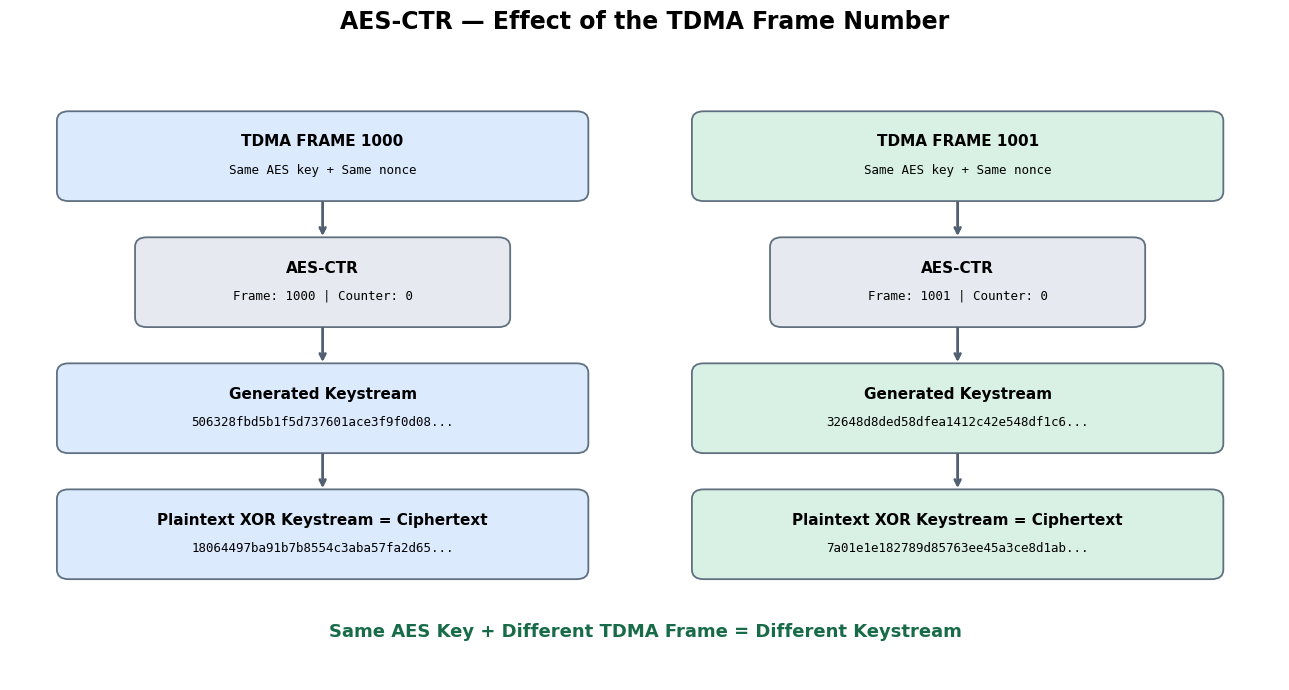

Ciphertexts differ: True


In [ ]:

# ============================================================
# part5: GSM SECURITY LAB — AES-CTR RADIO ENCRYPTION
# CELL 1: SECURITY EXPERIMENT
#A5
# ============================================================

import secrets
from cryptography.hazmat.primitives.ciphers import (
    Cipher, algorithms, modes
)

# AES-CTR is used for teaching, NOT actual GSM A5 encryption.


# STEP 1 — Prepare the message.
message = "Hello Bob, the meeting starts at 10:00."
plaintext = message.encode("utf-8")  # Convert text into bytes.


# STEP 2 — Generate a shared AES key and nonce.
radio_key = secrets.token_bytes(16)  # 128-bit AES key.
nonce = secrets.token_bytes(8)       # 64-bit random nonce.

# Define the GSM TDMA frame number.
frame_number = 1000

# Define the initial AES block counter.
block_counter = 0


# STEP 3 — Define encryption and decryption functions.
def encrypt(key, nonce, frame, counter, data):

    # Build the 128-bit initial AES-CTR input:
    # 8-byte nonce + 4-byte frame + 4-byte block counter.
    initial_counter = (
        nonce
        + frame.to_bytes(4, "big")
        + counter.to_bytes(4, "big")
    )

    # Create an AES cipher in CTR mode.
    cipher = Cipher(
        algorithms.AES(key),
        modes.CTR(initial_counter)
    )

    # Encrypt the data.
    # AES-CTR automatically increments the counter.
    encryptor = cipher.encryptor()
    #keystream is generated internally by AES-CTR when call encryptor.update(data)
    return encryptor.update(data) + encryptor.finalize()


def decrypt(key, nonce, frame, counter, ciphertext):

    # AES-CTR uses the same operation for decryption.
    return encrypt(key, nonce, frame, counter, ciphertext)


print("ORIGINAL MESSAGE:", message)


# ============================================================
# SCENARIO A — ENCRYPTED RADIO LINK
# ============================================================

# Mobile encrypts the message before radio transmission.
radio_ciphertext = encrypt(
    radio_key, nonce, frame_number, block_counter, plaintext
)

print("\nSCENARIO A — MOBILE TO BTS")
print("TDMA frame number:", frame_number)
print("Initial block counter:", block_counter)
print("Radio observer sees:", radio_ciphertext.hex())

# BTS decrypts using the same key, nonce, frame and counter.
bts_plaintext = decrypt(
    radio_key, nonce, frame_number, block_counter,
    radio_ciphertext
)

print("BTS recovers:", bts_plaintext.decode("utf-8"))
print("Decryption successful:", bts_plaintext == plaintext)


# ============================================================
# SCENARIO B — CHANGE THE TDMA FRAME NUMBER
# ============================================================

# Change the TDMA frame number.
new_frame_number = 1001

# Encrypt the SAME message using the SAME key and nonce,
# but a DIFFERENT frame number.
new_ciphertext = encrypt(
    radio_key, nonce, new_frame_number,
    block_counter, plaintext
)

print("\nSCENARIO B — NEW TDMA FRAME")
print("Original frame:", frame_number)
print("New frame:", new_frame_number)

print("Original ciphertext:", radio_ciphertext.hex())
print("New ciphertext:     ", new_ciphertext.hex())

print("Ciphertexts differ:", radio_ciphertext != new_ciphertext)

# ============================================================
# GSM AES-CTR — FRAME NUMBER AND CIPHERTEXT VISUALIZATION
# Run after the AES-CTR encryption experiment.
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# STEP 1 — Create the figure.
fig, ax = plt.subplots(figsize=(13, 7))

ax.set_xlim(0, 13)
ax.set_ylim(0, 8)
ax.axis("off")


# STEP 2 — Define a function to draw a labeled box.
def draw_box(x, y, width, height, title, value, color):

    # Create a rounded rectangle.
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.12",
        facecolor=color,
        edgecolor="#607080",
        linewidth=1.3
    )

    ax.add_patch(box)

    # Display the title inside the box.
    ax.text(
        x + width / 2, y + height * 0.7,
        title,
        ha="center", va="center",
        fontsize=11, fontweight="bold"
    )

    # Display the value inside the box.
    ax.text(
        x + width / 2, y + height * 0.3,
        value,
        ha="center", va="center",
        fontsize=9, family="monospace"
    )


# STEP 3 — Define a function to draw arrows.
def draw_arrow(x1, y1, x2, y2):

    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            color="#506070",
            linewidth=2
        )
    )


# STEP 4 — Compare two TDMA frame numbers.
frames = [1000, 1001]

# Use different colors for the two scenarios.
colors = ["#DCEAFE", "#D9F1E4"]

# Store the ciphertexts for comparison.
ciphertexts = []

for i, frame in enumerate(frames):

    # Position each scenario on the diagram.
    x = 0.6 + i * 6.5

    # Generate a keystream by encrypting zero bytes.
    # AES-CTR XORs its keystream with the input.
    # Zero XOR keystream = keystream.
    keystream = encrypt(
        radio_key,
        nonce,
        frame,
        block_counter,
        bytes(len(plaintext))
    )

    # Encrypt the original message using AES-CTR.
    encrypted = encrypt(
        radio_key,
        nonce,
        frame,
        block_counter,
        plaintext
    )

    # Save the ciphertext for comparison.
    ciphertexts.append(encrypted)

    # Show the shared key and frame number.
    draw_box(
        x, 6.2, 5.2, 0.9,
        f"TDMA FRAME {frame}",
        "Same AES key + Same nonce",
        colors[i]
    )

    draw_arrow(x + 2.6, 6.1, x + 2.6, 5.6)

    # Show AES-CTR and its input parameters.
    draw_box(
        x + 0.8, 4.6, 3.6, 0.9,
        "AES-CTR",
        f"Frame: {frame} | Counter: {block_counter}",
        "#E6E9EF"
    )

    draw_arrow(x + 2.6, 4.5, x + 2.6, 4.0)

    # Display the generated keystream.
    draw_box(
        x, 3.0, 5.2, 0.9,
        "Generated Keystream",
        keystream.hex()[:32] + "...",
        colors[i]
    )

    draw_arrow(x + 2.6, 2.9, x + 2.6, 2.4)

    # Display the ciphertext.
    draw_box(
        x, 1.4, 5.2, 0.9,
        "Plaintext XOR Keystream = Ciphertext",
        encrypted.hex()[:32] + "...",
        colors[i]
    )


# STEP 5 — Display the comparison result.
different = ciphertexts[0] != ciphertexts[1]

ax.text(
    6.5, 0.55,
    "Same AES Key + Different TDMA Frame = Different Keystream",
    ha="center",
    fontsize=13,
    fontweight="bold",
    color="#176B48"
)

# Add the diagram title.
ax.set_title(
    "AES-CTR — Effect of the TDMA Frame Number",
    fontsize=17,
    fontweight="bold",
    pad=15
)

plt.tight_layout()
plt.show()

print("Ciphertexts differ:", different)


**Instructor checkpoint:** A fresh RAND invalidates a recorded response in this example. The notebook does not implement a real GSM signaling replay.


## Part 6 — Backhaul Eavesdropping:
## Why Radio Encryption Is Not End-to-End Encryption

### Learning Objectives

After this experiment, students should be able to:

- Distinguish radio-link encryption from end-to-end encryption.
- Explain where GSM air-interface encryption terminates.
- Identify the security risk of an unencrypted backhaul link.
- Explain how additional backhaul encryption reduces exposure.

### Background

In GSM, air-interface encryption protects communication
between the Mobile Station (MS) and the Base Transceiver
Station (BTS).

However, protecting the radio interface does not
automatically protect the entire communication path.

Consider the following simplified architecture:

Mobile Station → BTS → Microwave Backhaul → MSC

Assume that:

1. The mobile-to-BTS radio link is encrypted.
2. The BTS decrypts the radio traffic.
3. The BTS forwards the recovered message over an
   unencrypted backhaul link.
4. An attacker can observe that backhaul link.

Under these assumptions, the attacker can read the message
even though the original radio transmission was encrypted.

### Experiment

We compare three situations:

| Scenario | Communication link | Attacker observes |
|---|---|---|
| A | Encrypted mobile-to-BTS link | Ciphertext |
| B | Unencrypted BTS-to-MSC backhaul | Plaintext |
| C | Encrypted BTS-to-MSC backhaul | Ciphertext |

### Important Technical Notes

- This is a simplified demonstration, not an implementation
  of GSM A5/1 or A5/3.
- We use a modern authenticated encryption algorithm to
  illustrate encryption and decryption.
- In a real GSM architecture, BTS, BSC, and MSC functions
  and transport links may be separated.
- Not all GSM microwave backhaul links are unencrypted.
- This simulation does not intercept actual network traffic.

### Questions for Students

1. Why can the backhaul attacker read the message in Scenario B?
2. Does encryption between the mobile and BTS guarantee
   end-to-end confidentiality?
3. What changes when backhaul encryption is enabled?
4. Would encrypting the message end-to-end protect it even
   if an intermediate transport link were unencrypted?


ORIGINAL MESSAGE: Hello Bob, the meeting starts at 10:00.

SCENARIO A — MOBILE TO BTS
Radio observer sees: 79f3a7549124c50f28092b4a58ac6f60492977f1d00e9be82c1e4530063f2f9a88a0754fc28f266dd56836444edd29ed78673dc655a758
BTS recovers: Hello Bob, the meeting starts at 10:00.

SCENARIO B — UNENCRYPTED BACKHAUL
Attacker reads: Hello Bob, the meeting starts at 10:00.

SCENARIO C — ENCRYPTED BACKHAUL
Attacker sees: df5a9c462dca9cd894dd21ba4ee34ba8b3bb24ab363287936ee695f443d81bac6b3ee76f9aa0c6c416019f6a7c7bd961819a677bd9e273
MSC recovers: Hello Bob, the meeting starts at 10:00.

CONCLUSION:
Radio encryption alone is not end-to-end encryption.
An unencrypted backhaul can expose the message.


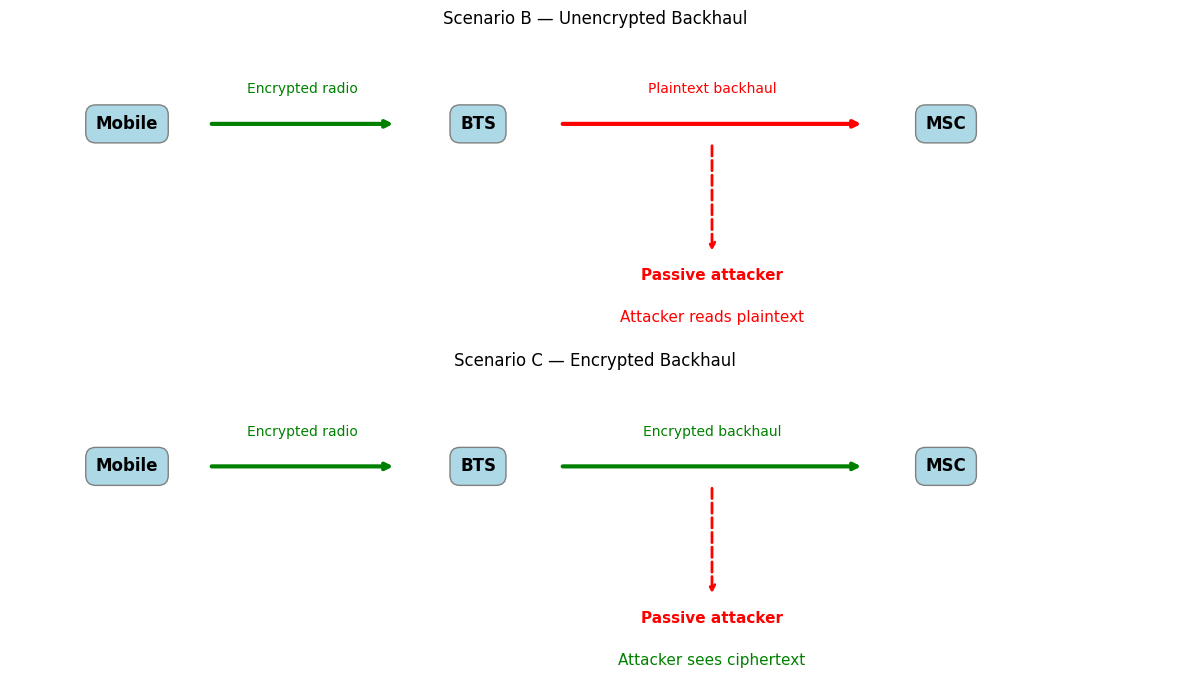

In [ ]:
# ============================================================
# GSM SECURITY LAB — BACKHAUL EAVESDROPPING
# CELL 1: SECURITY EXPERIMENT
# ============================================================

import secrets
from cryptography.hazmat.primitives.ciphers.aead import AESGCM

# AES-GCM is used for teaching, NOT actual GSM A5 encryption.

# STEP 1 — Prepare the message.
message = "Hello Bob, the meeting starts at 10:00."
plaintext = message.encode("utf-8")     #.encode("utf-8") → Converts the string into bytes.

# STEP 2 — Create separate keys for the radio and backhaul.
radio_key = AESGCM.generate_key(bit_length=256)
backhaul_key = AESGCM.generate_key(bit_length=256)

# STEP 3 — Define encryption and decryption functions.
def encrypt(key, data):
    # Create an AES-GCM cipher with the provided key.
    cipher = AESGCM(key)

    # Generate a fresh nonce for this encryption.
    nonce = secrets.token_bytes(12)

    # Return the nonce and encrypted data.
    return nonce, cipher.encrypt(nonce, data, None)


def decrypt(key, nonce, ciphertext):
    # Recover the original data using the correct key.
    return AESGCM(key).decrypt(nonce, ciphertext, None)


print("ORIGINAL MESSAGE:", message)


# ============================================================
# SCENARIO A — ENCRYPTED RADIO LINK
# ============================================================

# Mobile encrypts the message before radio transmission.
radio_nonce, radio_ciphertext = encrypt(radio_key, plaintext)

print("\nSCENARIO A — MOBILE TO BTS")
print("Radio observer sees:", radio_ciphertext.hex())

# BTS decrypts the radio message.
bts_plaintext = decrypt(
    radio_key, radio_nonce, radio_ciphertext
)

print("BTS recovers:", bts_plaintext.decode("utf-8"))


# ============================================================
# SCENARIO B — UNENCRYPTED BACKHAUL
# ============================================================

# Assume the BTS forwards plaintext without protection.
backhaul_payload = bts_plaintext

# A passive attacker observing this link reads the message.
print("\nSCENARIO B — UNENCRYPTED BACKHAUL")
print("Attacker reads:", backhaul_payload.decode("utf-8"))


# ============================================================
# SCENARIO C — ENCRYPTED BACKHAUL
# ============================================================

# BTS encrypts the message before forwarding it.
backhaul_nonce, backhaul_ciphertext = encrypt(
    backhaul_key, bts_plaintext
)

print("\nSCENARIO C — ENCRYPTED BACKHAUL")
print("Attacker sees:", backhaul_ciphertext.hex())

# MSC decrypts the protected backhaul transmission.
msc_plaintext = decrypt(
    backhaul_key, backhaul_nonce, backhaul_ciphertext
)

print("MSC recovers:", msc_plaintext.decode("utf-8"))


print("\nCONCLUSION:")
print("Radio encryption alone is not end-to-end encryption.")
print("An unencrypted backhaul can expose the message.")
# ============================================================
# CELL 2 — VISUALIZE THE BACKHAUL ATTACK
# ============================================================

import matplotlib.pyplot as plt

# Draw one network architecture with its security status.
def draw_network(ax, protected):

    ax.set_xlim(0, 10)
    ax.set_ylim(0, 4)
    ax.axis("off")

    # Network components and their positions.
    nodes = [
        (1, "Mobile"),
        (4, "BTS"),
        (8, "MSC")
    ]

    # Draw the components.
    for x, name in nodes:
        ax.text(
            x, 2.8, name,
            ha="center", va="center",
            fontsize=12, fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.6",
                facecolor="lightblue",
                edgecolor="gray"
            )
        )

    # Radio communication is encrypted.
    ax.annotate(
        "", xy=(3.3, 2.8), xytext=(1.7, 2.8),
        arrowprops=dict(arrowstyle="->", color="green", lw=3)
    )

    ax.text(
        2.5, 3.2, "Encrypted radio",
        ha="center", color="green", fontsize=10
    )

    # Backhaul protection changes between scenarios.
    link_color = "green" if protected else "red"
    link_label = "Encrypted backhaul" if protected else "Plaintext backhaul"

    ax.annotate(
        "", xy=(7.3, 2.8), xytext=(4.7, 2.8),
        arrowprops=dict(arrowstyle="->", color=link_color, lw=3)
    )

    ax.text(
        6, 3.2, link_label,
        ha="center", color=link_color, fontsize=10
    )

    # The attacker observes the backhaul link.
    ax.annotate(
        "", xy=(6, 1.1), xytext=(6, 2.55),
        arrowprops=dict(
            arrowstyle="->",
            linestyle="--",
            color="red",
            lw=2
        )
    )

    ax.text(
        6, 0.75, "Passive attacker",
        ha="center",
        fontsize=11,
        fontweight="bold",
        color="red"
    )

    # Display the attacker's observation.
    result = (
        "Attacker sees ciphertext"
        if protected
        else "Attacker reads plaintext"
    )

    ax.text(
        6, 0.2, result,
        ha="center",
        fontsize=11,
        color=link_color
    )


# Draw the vulnerable and protected scenarios.
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

draw_network(axes[0], protected=False)
axes[0].set_title("Scenario B — Unencrypted Backhaul")

draw_network(axes[1], protected=True)
axes[1].set_title("Scenario C — Encrypted Backhaul")

plt.tight_layout()
plt.show()


# part 7: GSM Security Lab — TMSI Identification, Authentication, and Reallocation

**Based on:** *Pseudonymization over the Air Interface (1)*

**Learning objectives:** Understand the difference between identification and authentication, how GSM protects subscriber identities, and how a new TMSI is assigned.

> **Note:** This notebook simulates the unknown-old-TMSI scenario shown in the slide. HMAC-SHA256 and AES-CTR are educational substitutes, not actual GSM A3/A8/A5 implementations.

## 1. GSM Identification and Authentication Process

### Step 1 — Mobile Sends Old TMSI and LAI

The mobile station (MS) sends its previously assigned TMSI and Location Area Identity (LAI).

```text
MS → Network
Old TMSI = A1B2C3D4
LAI = 262-01-1001
```

The TMSI helps avoid repeatedly exposing the permanent IMSI.

### Step 2 — VLR Attempts Identification

The Visitor Location Register (VLR) attempts to find the IMSI associated with the old TMSI.

- **Mapping succeeds:** The network identifies the subscriber and can proceed with authentication.
- **Mapping fails:** The network may request the permanent IMSI.

In this slide, **the mapping fails**.

### Step 3 — Identity Request and Response

The network requests the subscriber's IMSI.

```text
Network → MS: Identity Request
MS → Network: Identity Response (IMSI)
```

**Privacy risk:** If ciphering is not active, the IMSI can be exposed over the radio interface.

### Step 4 — Subscriber Authentication (A3)

The network sends a random challenge, `RAND`, to the SIM.

The SIM uses its secret key `Ki` to calculate:

\[
SRES=A3(K_i,RAND)
\]

The network compares the received SRES with the expected response.

- Match → Authentication succeeds.
- Mismatch → Authentication fails.

**Important:** TMSI mapping identifies the subscriber; A3 verifies possession of the subscriber's secret key.

### Step 5 — Session Key Derivation (A8)

The SIM and home network derive the ciphering key:

\[
K_c=A8(K_i,RAND)
\]

`Kc` is a 64-bit key used by GSM A5 ciphering.

**A8 generates Kc; A5 uses Kc.**

## 2. TMSI Reallocation

### Step 6 — Network Generates New TMSI

After successful identification and authentication, the VLR prepares a new temporary identity.

```text
Old TMSI = A1B2C3D4
New TMSI = 7F92E0AB
```

The network retains the necessary mapping information until reassignment is confirmed.

### Step 7 — Activate A5 Ciphering

GSM A5 uses `Kc` and radio frame information to protect radio communication.

Conceptually, for a stream-cipher variant:

\[
C=P\oplus Keystream
\]

In our Python simulation:

- **AES-CTR:** Provides confidentiality.
- **HMAC-SHA256:** Provides message integrity and authentication.

These are educational adaptations; classic GSM A5 does not provide cryptographic message integrity.

### Step 8 — TMSI Reallocation Command

The network sends the new TMSI over the ciphered radio connection.

```text
Network → MS
TMSI Reallocation Command
New TMSI = 7F92E0AB
```

The mobile decrypts the message and stores the new TMSI.

### Step 9 — Reallocation Complete

The mobile acknowledges successful reallocation.

```text
MS → Network
TMSI Reallocation Complete
```

The VLR can then remove the old TMSI mapping.

## 3. Summary of GSM Security Mechanisms

| Mechanism | Purpose |
|---|---|
| IMSI | Permanent subscriber identification |
| TMSI | Temporary identity for privacy |
| VLR mapping | Resolve TMSI to IMSI |
| A3 | Subscriber authentication |
| A8 | Derive session ciphering key `Kc` |
| A5 | Radio confidentiality |
| TMSI reallocation | Reduce subscriber tracking |
| AES-CTR (simulation) | Encryption |
| HMAC-SHA256 (simulation) | Integrity and message authentication |

## 4. Questions for Students

1. Why does the VLR perform TMSI-to-IMSI mapping before authentication?
2. What happens if the old TMSI cannot be recognized?
3. Why is successful mapping not sufficient for authentication?
4. What is the difference between A3, A8, and A5?
5. Why should the new TMSI be transmitted under ciphering?
6. What security property does HMAC-SHA256 add to our simulation?

## Key Takeaway

**Identification → Authentication → Key Derivation → Ciphering → TMSI Reallocation**

GSM uses TMSI to reduce exposure of the permanent IMSI, A3 to authenticate the subscriber, A8 to derive the ciphering key, and A5 to protect radio communication. TMSI reassignment further reduces the ability to track subscribers through a persistent temporary identifier.



STEP 1 — OLD TMSI IN SIM
Old TMSI: A1B2C3D4

STEP 2 — MS -> NETWORK
Message using old TMSI
LAI old: 262-01-1001
TMSI old: A1B2C3D4

STEP 3 — VLR: TMSI-IMSI MAPPING
Old TMSI: A1B2C3D4
Mapped IMSI: 262010123456789

STEP 4 — AUTHENTICATION
RAND: 2c4c51f2e40046f875af43d06b9a6015
SIM SRES: 97b372ef
Expected SRES: 97b372ef
Authentication successful: True
Kc: 412db72e2b74d19b

STEP 5 — VLR: TMSI REASSIGNMENT
Old TMSI: A1B2C3D4
New TMSI: 62086707

STEP 6 — SAVE NEW TMSI
VLR database: {'A1B2C3D4': '262010123456789', '62086707': '262010123456789'}

STEP 7 — BSC: CIPHER A5
New TMSI: 62086707
Encrypted TMSI: D6561F03

STEP 8 — NETWORK -> MS
TMSI Reallocation Command
Ciphered TMSI: D6561F03

STEP 9 — MS: A5 DECRYPTION
Recovered TMSI: 62086707
Save new TMSI in SIM: 62086707

STEP 10 — MS -> NETWORK
TMSI Reallocation Complete

STEP 11 — NETWORK: DELETE OLD TMSI
Old TMSI deleted: A1B2C3D4
New TMSI active: 62086707

FINAL STATE
SIM TMSI: 62086707
VLR: {'62086707': '262010123456789'}


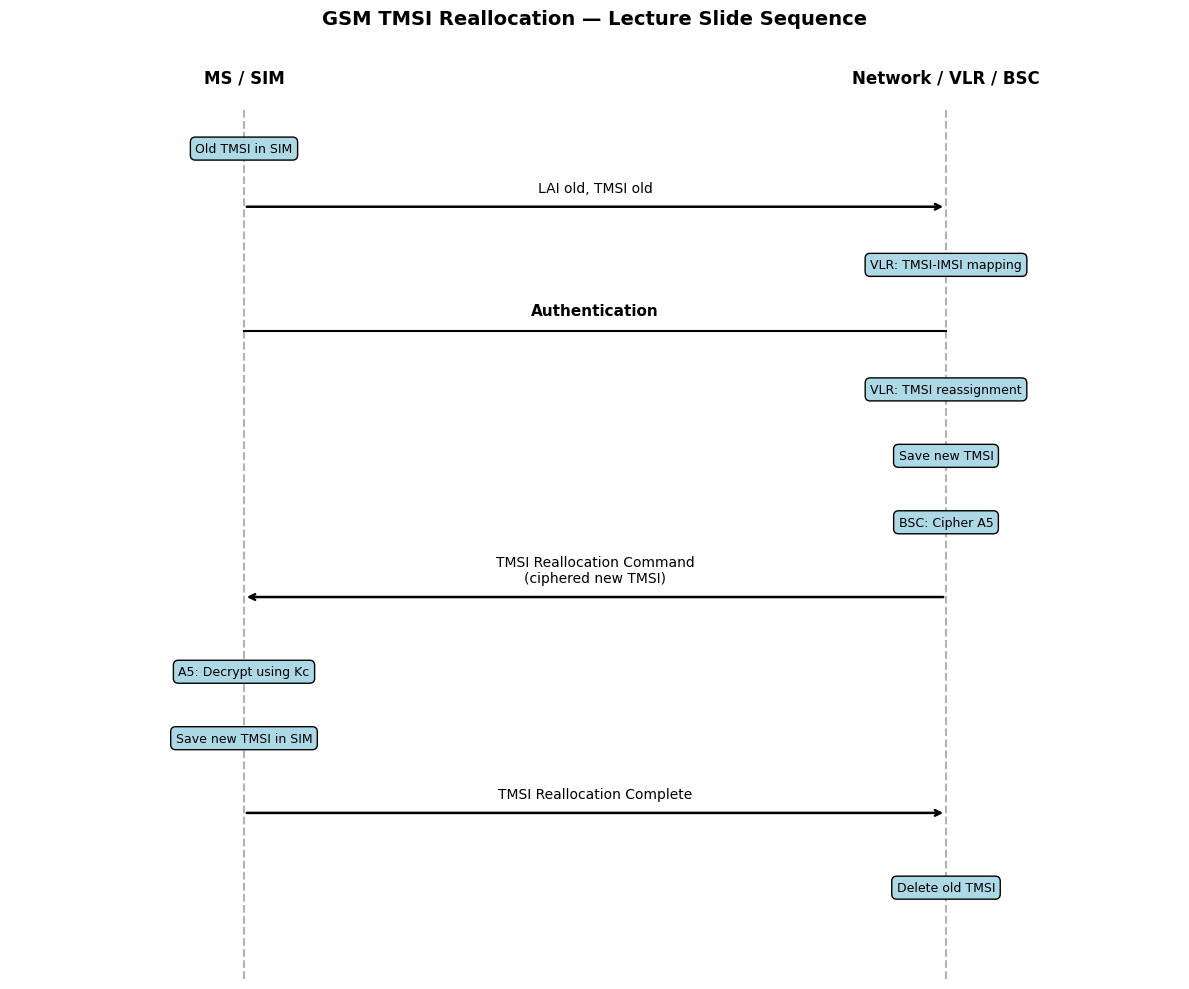

In [ ]:

# ============================================================
# GSM SECURITY LAB — TMSI REALLOCATION
# Follows the sequence in the lecture slide
#
# Educational simulation:
# A3/A8: HMAC-based teaching substitutes
# A5: simplified XOR keystream (NOT actual A5/1)
# No additional HMAC integrity layer
# ============================================================

import secrets
import hmac
import hashlib
import matplotlib.pyplot as plt


# ============================================================
# STEP 1 — OLD TMSI STORED IN SIM
# ============================================================

IMSI = "262010123456789"
LAI = "262-01-1001"

SIM_TMSI = "A1B2C3D4"

# VLR stores TMSI -> IMSI mapping
VLR = {SIM_TMSI: IMSI}

# Shared secret in SIM and AuC
Ki = secrets.token_bytes(16)

print("\nSTEP 1 — OLD TMSI IN SIM")
print("Old TMSI:", SIM_TMSI)


# ============================================================
# STEP 2 — MS SENDS OLD LAI AND OLD TMSI
# ============================================================

old_TMSI = SIM_TMSI

print("\nSTEP 2 — MS -> NETWORK")
print("Message using old TMSI")
print("LAI old:", LAI)
print("TMSI old:", old_TMSI)


# ============================================================
# STEP 3 — VLR: TMSI-IMSI MAPPING
# ============================================================

found_IMSI = VLR.get(old_TMSI)

if found_IMSI is None:
    raise ValueError("Unknown TMSI")

print("\nSTEP 3 — VLR: TMSI-IMSI MAPPING")
print("Old TMSI:", old_TMSI)
print("Mapped IMSI:", found_IMSI)


# ============================================================
# STEP 4 — AUTHENTICATION
# ============================================================

# Teaching substitutes for GSM A3 and A8.
def A3(key, rand):
    return hmac.new(
        key, b"A3" + rand, hashlib.sha256
    ).digest()[:4]

def A8(key, rand):
    return hmac.new(
        key, b"A8" + rand, hashlib.sha256
    ).digest()[:8]


# Network generates authentication challenge
RAND = secrets.token_bytes(16)

# SIM computes SRES
SIM_SRES = A3(Ki, RAND)

# Network has expected SRES from AuC
expected_SRES = A3(Ki, RAND)

authenticated = hmac.compare_digest(
    SIM_SRES, expected_SRES
)

if not authenticated:
    raise ValueError("Authentication failed")

# Both sides obtain the same 64-bit Kc
SIM_Kc = A8(Ki, RAND)
NETWORK_Kc = A8(Ki, RAND)

print("\nSTEP 4 — AUTHENTICATION")
print("RAND:", RAND.hex())
print("SIM SRES:", SIM_SRES.hex())
print("Expected SRES:", expected_SRES.hex())
print("Authentication successful:", authenticated)
print("Kc:", SIM_Kc.hex())


# ============================================================
# STEP 5 — VLR: TMSI REASSIGNMENT
# ============================================================

new_TMSI = secrets.token_hex(4).upper()

while new_TMSI in VLR:
    new_TMSI = secrets.token_hex(4).upper()

print("\nSTEP 5 — VLR: TMSI REASSIGNMENT")
print("Old TMSI:", old_TMSI)
print("New TMSI:", new_TMSI)


# ============================================================
# STEP 6 — SAVE NEW TMSI IN NETWORK
# ============================================================

# Keep old mapping until reallocation completes.
VLR[new_TMSI] = found_IMSI

print("\nSTEP 6 — SAVE NEW TMSI")
print("VLR database:", VLR)


# ============================================================
# STEP 7 — BSC: CIPHER A5
# ============================================================

# Simplified teaching cipher.
# NOT a real implementation of GSM A5/1.
#
# A5 concept:
#   Kc -> keystream
#   plaintext XOR keystream -> ciphertext
#
# Receiver XORs the same keystream to decrypt.

def A5_teaching(kc, data):
    keystream = hashlib.sha256(
        b"A5-TEACHING" + kc
    ).digest()

    return bytes(
        byte ^ keystream[i]
        for i, byte in enumerate(data)
    )


# New TMSI as 4 bytes
plaintext = bytes.fromhex(new_TMSI)

# Network encrypts
ciphertext = A5_teaching(
    NETWORK_Kc, plaintext
)

print("\nSTEP 7 — BSC: CIPHER A5")
print("New TMSI:", plaintext.hex().upper())
print("Encrypted TMSI:", ciphertext.hex().upper())


# ============================================================
# STEP 8 — TMSI REALLOCATION COMMAND
# ============================================================

# Network sends ciphered new TMSI to MS
received_ciphertext = ciphertext

print("\nSTEP 8 — NETWORK -> MS")
print("TMSI Reallocation Command")
print("Ciphered TMSI:", received_ciphertext.hex().upper())


# ============================================================
# STEP 9 — MS: A5 DECRYPTION AND SAVE NEW TMSI
# ============================================================

# MS uses its Kc to recover the new TMSI
decrypted = A5_teaching(
    SIM_Kc, received_ciphertext
)

SIM_TMSI = decrypted.hex().upper()

print("\nSTEP 9 — MS: A5 DECRYPTION")
print("Recovered TMSI:", SIM_TMSI)
print("Save new TMSI in SIM:", SIM_TMSI)


# ============================================================
# STEP 10 — TMSI REALLOCATION COMPLETE
# ============================================================

if SIM_TMSI != new_TMSI:
    raise ValueError("TMSI reallocation failed")

print("\nSTEP 10 — MS -> NETWORK")
print("TMSI Reallocation Complete")


# ============================================================
# STEP 11 — DELETE OLD TMSI
# ============================================================

del VLR[old_TMSI]

print("\nSTEP 11 — NETWORK: DELETE OLD TMSI")
print("Old TMSI deleted:", old_TMSI)
print("New TMSI active:", SIM_TMSI)

print("\nFINAL STATE")
print("SIM TMSI:", SIM_TMSI)
print("VLR:", VLR)


# ============================================================
# COMMUNICATION DIAGRAM — SAME ORDER AS LECTURE SLIDE
# ============================================================

fig, ax = plt.subplots(figsize=(12, 10))

x_ms = 1.5
x_network = 9

# Lifelines
for x, name in [(x_ms, "MS / SIM"),
                (x_network, "Network / VLR / BSC")]:
    ax.plot([x, x], [0.5, 11.5],
            "--", color="gray", alpha=0.6)
    ax.text(x, 11.8, name, ha="center",
            fontsize=12, fontweight="bold")


def arrow(x1, x2, y, label):
    ax.annotate(
        "", xy=(x2, y), xytext=(x1, y),
        arrowprops=dict(arrowstyle="->", lw=1.8)
    )
    ax.text(
        (x1 + x2) / 2, y + 0.18,
        label, ha="center", fontsize=10
    )


def operation(x, y, label):
    ax.text(
        x, y, label,
        ha="center", va="center",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.4",
                  facecolor="lightblue",
                  edgecolor="black")
    )


# Initial state
operation(x_ms, 11, "Old TMSI in SIM")

# Identification
arrow(x_ms, x_network, 10.3,
      "LAI old, TMSI old")

operation(x_network, 9.6,
          "VLR: TMSI-IMSI mapping")

# Authentication
ax.plot([x_ms, x_network], [8.8, 8.8],
        color="black", lw=1.5)
ax.text(5.25, 9.0, "Authentication",
        ha="center", fontsize=11,
        fontweight="bold")

# Reassignment
operation(x_network, 8.1,
          "VLR: TMSI reassignment")

operation(x_network, 7.3,
          "Save new TMSI")

operation(x_network, 6.5,
          "BSC: Cipher A5")

# Reallocation command
arrow(x_network, x_ms, 5.6,
      "TMSI Reallocation Command\n(ciphered new TMSI)")

# MS processing
operation(x_ms, 4.7,
          "A5: Decrypt using Kc")

operation(x_ms, 3.9,
          "Save new TMSI in SIM")

# Completion
arrow(x_ms, x_network, 3.0,
      "TMSI Reallocation Complete")

# Delete old TMSI
operation(x_network, 2.1,
          "Delete old TMSI")

ax.set_xlim(-1, 11.5)
ax.set_ylim(1, 12.4)
ax.axis("off")

plt.title(
    "GSM TMSI Reallocation — Lecture Slide Sequence",
    fontsize=14, fontweight="bold"
)

plt.tight_layout()
plt.show()



## Part 8 — TMSI Privacy: Can a Subscriber Be Tracked?

### Learning Objectives

After this experiment, students should be able to:

- Explain the difference between IMSI and TMSI.
- Understand why GSM uses temporary subscriber identifiers.
- Identify how repeated identifiers enable activity linking.
- Explain why changing TMSI improves privacy but does not
  guarantee anonymity.

### Background

**IMSI (International Mobile Subscriber Identity)**

- A permanent subscriber identifier stored in the SIM.
- Used by the mobile network to identify the subscriber.
- Repeated exposure can make subscriber activity easier to link.

**TMSI (Temporary Mobile Subscriber Identity)**

- A temporary identifier assigned by the serving network.
- Helps avoid transmitting IMSI unnecessarily.
- Can be reassigned to reduce direct identifier linkability.
- Is meaningful within the relevant serving-network context.

### Experiment

Imagine a subscriber performing five activities:

1. Sending a message
2. Making a call
3. Accessing a network service
4. Making another call
5. Sending another message

We compare three hypothetical scenarios:

| Scenario | Identifier behavior | Privacy consequence |
|---|---|---|
| A | Same TMSI across all activities | Activities directly linkable |
| B | Different TMSI for every activity | Direct identifier matching prevented |
| C | Same IMSI exposed repeatedly | Activities linkable using a permanent identity |

Scenario B is an idealized example of frequent reassignment,
not a claim that GSM changes TMSI after every activity.

### Important Security Concept: Linkability

**Linkability** means determining whether two or more
observations belong to the same subscriber.

A repeated TMSI allows an observer to associate activities
without necessarily knowing the subscriber's real identity.

Changing TMSI reduces direct identifier matching, but
tracking may still be possible through timing, location,
radio characteristics, or other information.

### Questions

1. Why is transmitting IMSI repeatedly a privacy risk?
2. Does a repeated TMSI reveal the subscriber's real name?
3. Can activities be linked even when the TMSI changes?
4. Does changing TMSI guarantee anonymity?



SAME TMSI
Send message       | 2B0AA4E3
Make call          | 2B0AA4E3
Access service     | 2B0AA4E3
Make call          | 2B0AA4E3
Send message       | 2B0AA4E3

Unique identifiers: 1
All five activities directly linkable: YES

CHANGING TMSI
Send message       | E592FE34
Make call          | FD16CE59
Access service     | AB3FB6E8
Make call          | F3CDA549
Send message       | 294F7D3F

Unique identifiers: 5
All five activities directly linkable: NO
(Based on identifier equality alone)

IMSI EXPOSED
Send message       | 262011234567890
Make call          | 262011234567890
Access service     | 262011234567890
Make call          | 262011234567890
Send message       | 262011234567890

Unique identifiers: 1
All five activities directly linkable: YES
GSM PRIVACY: TMSI TRACKING DEMONSTRATION

--- Same TMSI ---
Activity 1: 4B2EEB06
Activity 2: 4B2EEB06
Activity 3: 4B2EEB06
Activity 4: 4B2EEB06
Activity 5: 4B2EEB06
Unique identifiers: 1
All activities linkable by identifier: True

--- Chang

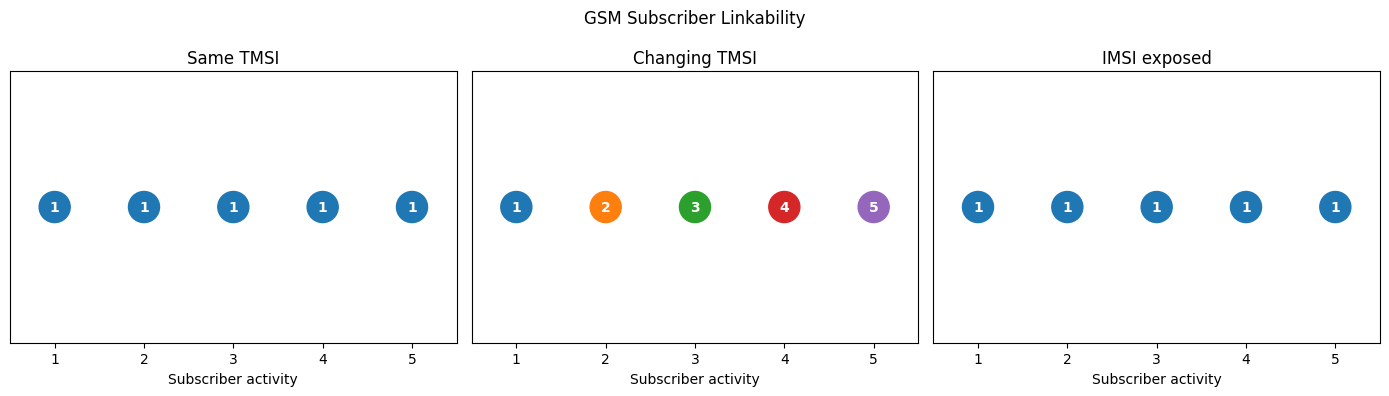


CONCLUSION:
Same TMSI: Activities can be linked.
Changing TMSI: Direct identifier linking is reduced.
IMSI exposure: Permanent identity can be tracked.
TMSI alone does not guarantee anonymity.


In [ ]:

# ============================================================
# GSM SECURITY LAB — PART 5
# TMSI Privacy and Subscriber Linkability
# CELL 2: SECURITY EXPERIMENT
# ============================================================

import secrets

# STEP 1 — Define a fictional subscriber's permanent IMSI.
IMSI = "262011234567890"

# STEP 2 — Generate a random 32-bit temporary identifier.
def generate_tmsi():
    return secrets.token_hex(4).upper()


# STEP 3 — Simulate five subscriber activities.
activities = [
    "Send message",
    "Make call",
    "Access service",
    "Make call",
    "Send message"
]
#,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,#
# SCENARIO A — The same TMSI is reused.
fixed_tmsi = generate_tmsi()
same_tmsi = [fixed_tmsi] * 5

#´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´#
# SCENARIO B — A new TMSI is assigned for each activity.
# Ensure all five identifiers are different.
changing_tmsi = []

while len(changing_tmsi) < 5:
    new_id = generate_tmsi()

    if new_id not in changing_tmsi:
        changing_tmsi.append(new_id)

#´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´´#
# SCENARIO C — The permanent IMSI is repeatedly exposed.
exposed_imsi = [IMSI] * 5

#`````````````````````````````````````````````````````````````````````````````````````````````````````````````````´#
# STEP 4 — Store the three scenarios for comparison.
scenarios = {
    "Same TMSI": same_tmsi,
    "Changing TMSI": changing_tmsi,
    "IMSI exposed": exposed_imsi
}


# STEP 5 — Examine what an observer can link.
for scenario, identifiers in scenarios.items():

    print("\n" + "=" * 55)
    print(scenario.upper())
    print("=" * 55)

    # Display the identifier visible for each activity.
    for activity, identifier in zip(activities, identifiers):
        print(f"{activity:18} | {identifier}")

    # A repeated identifier allows direct matching.
    unique_count = len(set(identifiers))

    print("\nUnique identifiers:", unique_count)

    if unique_count == 1:
        print("All five activities directly linkable: YES")
    else:
        print("All five activities directly linkable: NO")
        print("(Based on identifier equality alone)")





# Load the Python module or helper needed for this exercise.
import secrets
# Load the Python module or helper needed for this exercise.
import matplotlib.pyplot as plt

# Display a label or calculated value so students can inspect the result.
print("=" * 55)
# Display a label or calculated value so students can inspect the result.
print("GSM PRIVACY: TMSI TRACKING DEMONSTRATION")
# Display a label or calculated value so students can inspect the result.
print("=" * 55)

# Fictional permanent subscriber identity
# Assign the computed value to a variable for use in subsequent steps.
IMSI = "262011234567890"

# Define a reusable function; the indented lines below form its body.
def new_tmsi(used):
    # Repeat the indented operations while this condition remains true.
    while True:
        value = secrets.token_hex(4).upper()
        # Test the condition before executing the indented branch.
        if value not in used:
            # Return the calculated result to the caller.
            return value

# Scenario 1: Same TMSI for all five activities
# Assign the computed value to a variable for use in subsequent steps.
fixed_tmsi = new_tmsi(set())
# Assign the computed value to a variable for use in subsequent steps.
same_ids = [fixed_tmsi] * 5

# Scenario 2: TMSI reassigned for each activity
# Assign the computed value to a variable for use in subsequent steps.
changed_ids = []
# Iterate over the items in this sequence.
for i in range(5):
    changed_ids.append(new_tmsi(set(changed_ids)))

# Scenario 3: Permanent IMSI is exposed
# Assign the computed value to a variable for use in subsequent steps.
exposed_ids = [IMSI] * 5

# Assign the computed value to a variable for use in subsequent steps.
scenarios = [
    ("Same TMSI", same_ids),
    ("Changing TMSI", changed_ids),
    ("IMSI exposed", exposed_ids)
]

# Iterate over the items in this sequence.
for title, identifiers in scenarios:
    # Display a label or calculated value so students can inspect the result.
    print(f"\n--- {title} ---")
    # Iterate over the items in this sequence.
    for i, identifier in enumerate(identifiers, 1):
        # Display a label or calculated value so students can inspect the result.
        print(f"Activity {i}: {identifier}")

    # Display a label or calculated value so students can inspect the result.
    print("Unique identifiers:", len(set(identifiers)))
    # Display a label or calculated value so students can inspect the result.
    print("All activities linkable by identifier:",
          len(set(identifiers)) == 1)

# Visualize identifiers as colored categories
# Create a Matplotlib figure and plotting area.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Iterate over the items in this sequence.
for ax, (title, identifiers) in zip(axes, scenarios):
    unique = list(dict.fromkeys(identifiers))
    codes = [unique.index(x) for x in identifiers]

    # Configure or draw an element of the teaching visualization.
    ax.scatter(range(1, 6), [1]*5,
               c=codes, cmap="tab10",
               vmin=0, vmax=9, s=500)

    # Iterate over the items in this sequence.
    for i, code in enumerate(codes, 1):
        # Configure or draw an element of the teaching visualization.
        ax.text(i, 1, str(code+1),
                ha="center", va="center",
                color="white", fontweight="bold")

    # Configure or draw an element of the teaching visualization.
    ax.set_xlim(0.5, 5.5)
    # Configure or draw an element of the teaching visualization.
    ax.set_ylim(0.5, 1.5)
    # Configure or draw an element of the teaching visualization.
    ax.set_xticks(range(1, 6))
    # Configure or draw an element of the teaching visualization.
    ax.set_yticks([])
    # Configure or draw an element of the teaching visualization.
    ax.set_xlabel("Subscriber activity")
    # Configure or draw an element of the teaching visualization.
    ax.set_title(title)

# Configure or draw an element of the teaching visualization.
plt.suptitle("GSM Subscriber Linkability")
# Configure or draw an element of the teaching visualization.
plt.tight_layout()
# Configure or draw an element of the teaching visualization.
plt.show()

# Display a label or calculated value so students can inspect the result.
print("\nCONCLUSION:")
# Display a label or calculated value so students can inspect the result.
print("Same TMSI: Activities can be linked.")
# Display a label or calculated value so students can inspect the result.
print("Changing TMSI: Direct identifier linking is reduced.")
# Display a label or calculated value so students can inspect the result.
print("IMSI exposure: Permanent identity can be tracked.")
# Display a label or calculated value so students can inspect the result.
print("TMSI alone does not guarantee anonymity.")



**Instructor checkpoint:** The keystream is used for XOR. Changing frame number alters the demo keystream; the example does not model GSM burst formatting.


## Part 9 — Inside GSM A5/1: Registers and Majority Clocking

### Learning Objectives

After this experiment, students should be able to:

- Identify the three A5/1 shift registers.
- Explain how Linear Feedback Shift Registers (LFSRs) work.
- Understand majority clocking.
- Explain why only two or three registers advance per step.
- Distinguish historical A5/1 from our earlier HMAC-based simulation.

### Background

A5/1 is a historical GSM stream cipher that uses three
Linear Feedback Shift Registers (LFSRs).

| Register | Length | Clock-Control Bit |
|----------|--------|-------------------|
| R1       | 19 bits | 8                 |
| R2       | 22 bits | 10                |
| R3       | 23 bits | 10                |

Each register stores a sequence of bits.

During clocking, feedback bits are calculated using XOR,
and the selected registers shift by one position.

### Majority Clocking

A5/1 does not always advance all three registers.

Instead:

1. Read the clock-control bit from each register.
2. Calculate the majority value (0 or 1).
3. Advance registers whose clock-control bit matches
   the majority.
4. Leave the remaining register unchanged.

Example:

R1 clock bit = 1
R2 clock bit = 0
R3 clock bit = 1

Majority = 1

Therefore:

- R1 advances.
- R2 remains unchanged.
- R3 advances.

### Keystream Generation

After initialization with Kc and the GSM frame number,
A5/1 performs 100 majority-clocked warm-up cycles.

It then produces 228 keystream bits:

- 114 bits for one transmission direction.
- 114 bits for the other transmission direction.

At each output step, the three register output bits
are combined using XOR.

### Important Note

This experiment implements the historical A5/1 design
for educational purposes.

A5/1 is a legacy cipher with known cryptographic weaknesses.
It should not be considered secure for modern applications.

### Discussion Questions

1. Why does A5/1 use three registers?
2. What is the purpose of majority clocking?
3. Why do at least two registers advance at each step?
4. What is the difference between A5/1 and our HMAC demo?


In [ ]:

# ============================================================
# GSM A5/1 — UNDERSTANDING MAJORITY CLOCKING
# ============================================================

# Example clock-control bits from the three registers.
R1_clock = 1
R2_clock = 0
R3_clock = 1

# The majority is the value appearing at least twice.
majority_bit = 1 if (
    R1_clock + R2_clock + R3_clock
) >= 2 else 0

print("A5/1 — MAJORITY CLOCKING")
print("-" * 40)

print("R1 clock bit:", R1_clock)
print("R2 clock bit:", R2_clock)
print("R3 clock bit:", R3_clock)

print("\nMajority bit:", majority_bit)

# A register advances only when its bit matches the majority.
print("\nClocking decisions:")

print("R1 advances:", R1_clock == majority_bit)
print("R2 advances:", R2_clock == majority_bit)
print("R3 advances:", R3_clock == majority_bit)


A5/1 — MAJORITY CLOCKING
----------------------------------------
R1 clock bit: 1
R2 clock bit: 0
R3 clock bit: 1

Majority bit: 1

Clocking decisions:
R1 advances: True
R2 advances: False
R3 advances: True



### Visual Lab — Understanding A5/1 Majority Clocking

#### Concept

A5/1 contains three Linear Feedback Shift Registers (LFSRs):

- R1: 19 bits
- R2: 22 bits
- R3: 23 bits

Each register has a clock-control bit.

At every output step:

1. Read the three clock-control bits.
2. Calculate their majority value.
3. Advance registers matching the majority.
4. Leave the remaining register unchanged.
5. XOR the output bits of all three registers.

#### Observe

The first diagram shows which registers advance during
one majority-clocking step.

The second diagram shows the first 64 bits of the
generated A5/1 keystream.

The keystream is not plaintext. It is combined with
plaintext using XOR to produce ciphertext.

#### Discussion Questions

1. Do all three registers always advance together?
2. Can a register advance when its clock-control bit is 0?
3. Why does the receiver need the same Kc and frame number?
4. Why does changing the frame number change the keystream?

**Run the next cell to visualize the A5/1 clocking process.**



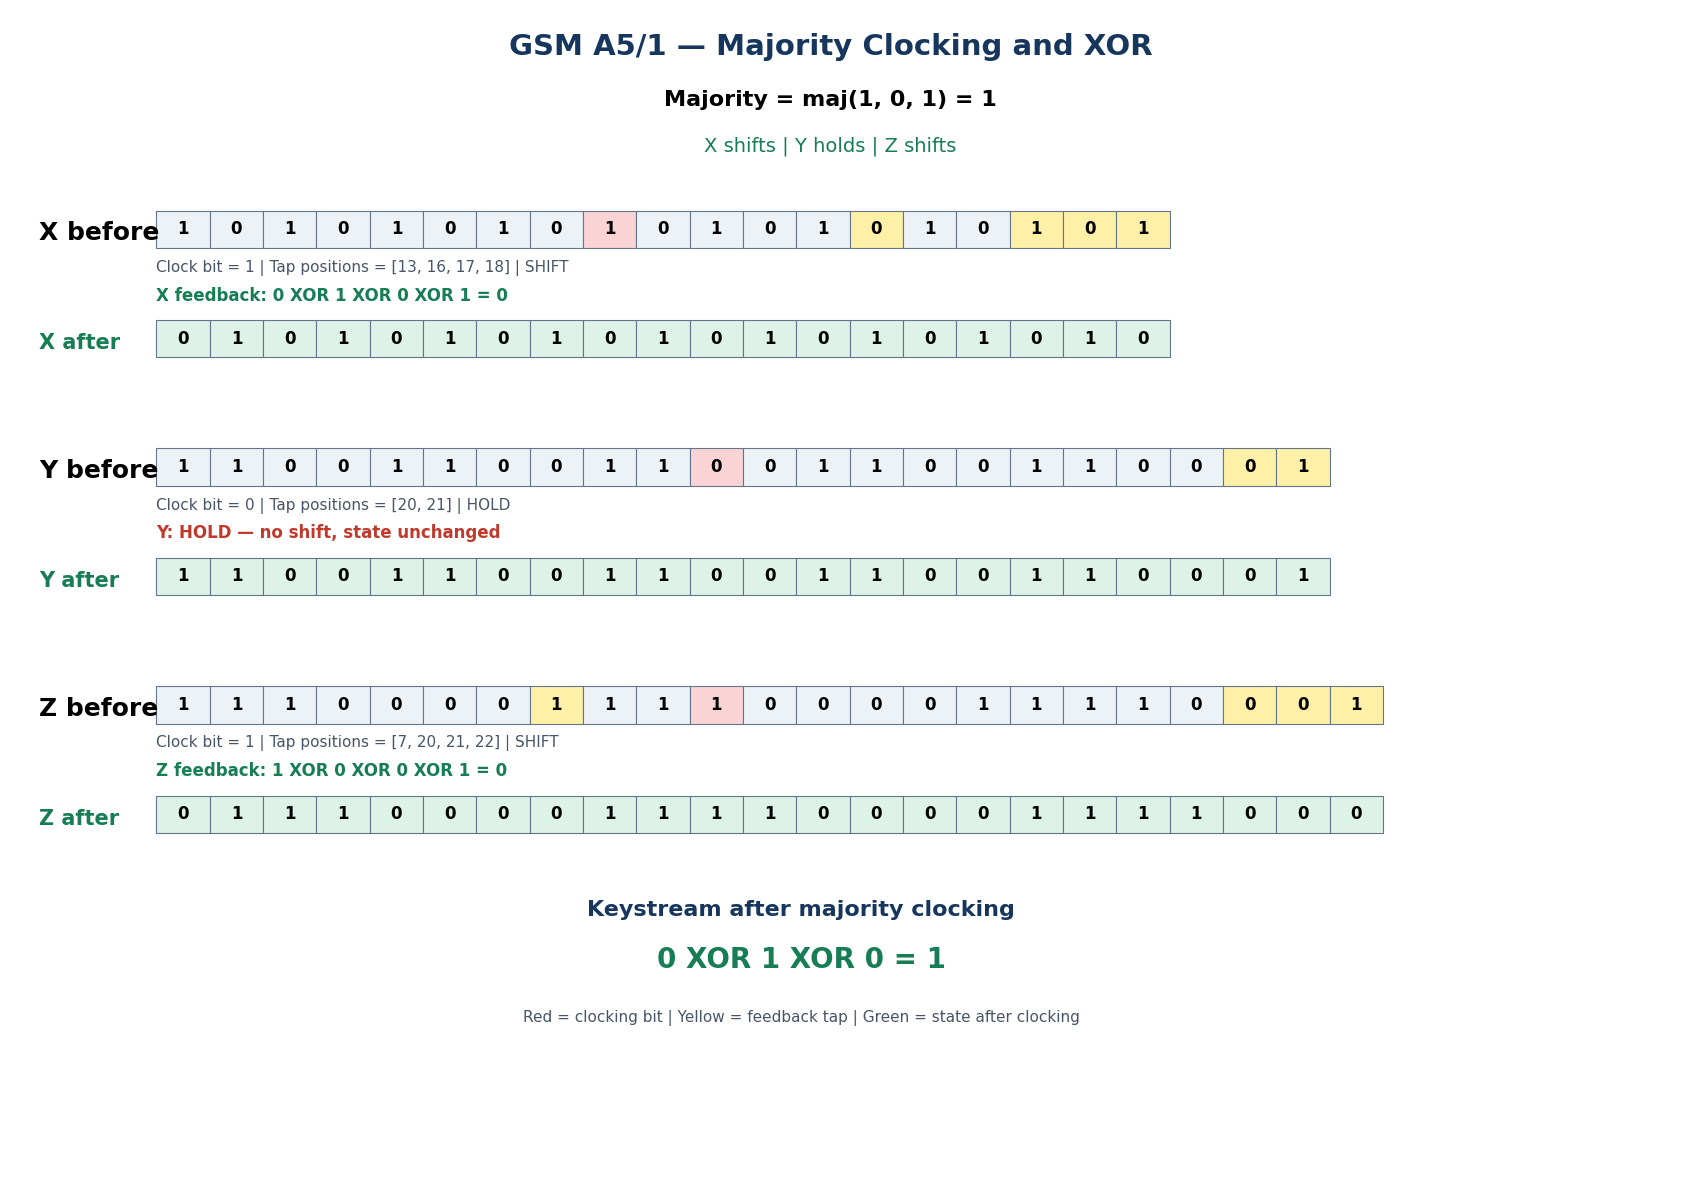

A5/1 — COMPLETE SLIDE EXAMPLE

CLOCKING BITS
X[8] = 1
Y[10] = 0
Z[10] = 1

Majority = 1

REGISTER FEEDBACK AND SHIFTING

Register X
Before: 1010101010101010101
Feedback: 0 XOR 1 XOR 0 XOR 1 = 0
Action: SHIFT
After:  0101010101010101010

Register Y
Before: 1100110011001100110001
Action: HOLD
After:  1100110011001100110001

Register Z
Before: 11100001111000011110001
Feedback: 1 XOR 0 XOR 0 XOR 1 = 0
Action: SHIFT
After:  01110000111100001111000

KEYSTREAM
Before clocking: 1 XOR 1 XOR 1 = 1
After clocking:  0 XOR 1 XOR 0 = 1

Final keystream bit: 1


In [ ]:

# ============================================================
# GSM A5/1 — COMPLETE SLIDE EXAMPLE
# Majority clocking + feedback XOR + shifting + keystream
# One self-contained Jupyter / Google Colab cell
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ------------------------------------------------------------
# STEP 1 — ORIGINAL REGISTERS FROM OUR SLIDE
# Bit 0 is displayed on the LEFT.
# ------------------------------------------------------------

states = {
    "X": "1010101010101010101",      # 19 bits
    "Y": "1100110011001100110001",   # 22 bits
    "Z": "11100001111000011110001"   # 23 bits
}

config = {
    "X": {"clock": 8,  "taps": [13, 16, 17, 18]},
    "Y": {"clock": 10, "taps": [20, 21]},
    "Z": {"clock": 10, "taps": [7, 20, 21, 22]}
}

assert [len(states[r]) for r in "XYZ"] == [19, 22, 23]

# ------------------------------------------------------------
# STEP 2 — FUNCTIONS
# ------------------------------------------------------------

def majority(a, b, c):
    return int(a + b + c >= 2)

def feedback_xor(bits, taps):
    values = [int(bits[i]) for i in taps] #reads the bits at positions 13, 16, 17, and 18.
    result = 0 # The result is: values = [0, 1, 0, 1]
    for value in values:
        result ^= value #result = result ^ value
    return values, result #return ([0, 1, 0, 1], 0)
    # ---------------------------------------
# Iteration | Operation | Result
# ---------------------------------------
# Initial   |     —     |   0
# 1         |  0 XOR 0  |   0
# 2         |  0 XOR 1  |   1
# 3         |  1 XOR 0  |   1
# 4         |  1 XOR 1  |   0
# ---------------------------------------
# Final feedback XOR = 0

def shift_register(bits, feedback):
    # Bit 0 is on the left.
    # Feedback enters at bit 0.
    return str(feedback) + bits[:-1] # bits[:-1]: keeps everything except the last character.

def xor_text(values):
    return " XOR ".join(map(str, values))

# ------------------------------------------------------------
# STEP 3 — CLOCKING DECISION
# ------------------------------------------------------------

clock_bits = {
    r: int(states[r][config[r]["clock"]])
    for r in "XYZ"
}

m = majority(
    clock_bits["X"],
    clock_bits["Y"],
    clock_bits["Z"]
)

clocked = {
    r: clock_bits[r] == m
    for r in "XYZ"
}

# ------------------------------------------------------------
# STEP 4 — FEEDBACK XOR AND SHIFT
# ------------------------------------------------------------

feedback_values = {}
feedback_results = {}
new_states = {}

for r in "XYZ":

    values, feedback = feedback_xor(
        states[r],
        config[r]["taps"]
    )

    feedback_values[r] = values
    feedback_results[r] = feedback

    if clocked[r]:
        new_states[r] = shift_register(states[r], feedback)
    else:
        new_states[r] = states[r]

# ------------------------------------------------------------
# STEP 5 — KEYSTREAM BEFORE AND AFTER CLOCKING
# ------------------------------------------------------------

old_output_bits = [
    int(states[r][-1]) for r in "XYZ"
]

new_output_bits = [
    int(new_states[r][-1]) for r in "XYZ"
]

old_keystream = (
    old_output_bits[0]
    ^ old_output_bits[1]
    ^ old_output_bits[2]
)

new_keystream = (
    new_output_bits[0]
    ^ new_output_bits[1]
    ^ new_output_bits[2]
)

# ------------------------------------------------------------
# STEP 6 — DRAW ALL REGISTERS AND CALCULATIONS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(17, 12))
ax.set_xlim(-2.5, 26)
ax.set_ylim(-2.2, 16)
ax.axis("off")

fig.patch.set_facecolor("white")

ax.text(
    11.5, 15.3,
    "GSM A5/1 — Majority Clocking and XOR",
    fontsize=21, fontweight="bold",
    ha="center", color="#17365D"
)

ax.text(
    11.5, 14.5,
    f"Majority = maj({clock_bits['X']}, "
    f"{clock_bits['Y']}, {clock_bits['Z']}) = {m}",
    fontsize=16, fontweight="bold",
    ha="center"
)

ax.text(
    11.5, 13.8,
    "X shifts | Y holds | Z shifts",
    fontsize=14, ha="center",
    color="#167D54"
)

CELL_W = 0.91
CELL_H = 0.58

def draw_register(bits, name, y, clock, taps, caption):

    ax.text(
        -2.0, y + 0.12,
        name, fontsize=18,
        fontweight="bold"
    )

    for i, value in enumerate(bits):

        x = i * CELL_W

        if i == clock:
            color = "#FAD4D4"  # clocking bit
        elif i in taps:
            color = "#FFF0A8"  # feedback tap
        else:
            color = "#EDF2F7"

        ax.add_patch(
            Rectangle(
                (x, y), CELL_W, CELL_H,
                facecolor=color,
                edgecolor="#64748B",
                linewidth=0.8
            )
        )

        ax.text(
            x + CELL_W / 2,
            y + CELL_H / 2,
            value,
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold"
        )

    ax.text(
        0, y - 0.37,
        caption,
        fontsize=11,
        color="#475569"
    )

def draw_after(bits, name, y):

    ax.text(
        -2.0, y + 0.12,
        name, fontsize=15,
        fontweight="bold",
        color="#167D54"
    )

    for i, value in enumerate(bits):

        x = i * CELL_W

        ax.add_patch(
            Rectangle(
                (x, y), CELL_W, CELL_H,
                facecolor="#DDF3E7",
                edgecolor="#64748B",
                linewidth=0.8
            )
        )

        ax.text(
            x + CELL_W / 2,
            y + CELL_H / 2,
            value,
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold"
        )

# Original states
before_y = {"X": 12.3, "Y": 8.6, "Z": 4.9}
after_y = {"X": 10.6, "Y": 6.9, "Z": 3.2}

for r in "XYZ":

    clock = config[r]["clock"]
    taps = config[r]["taps"]

    status = "SHIFT" if clocked[r] else "HOLD"

    draw_register(
        states[r],
        r + " before",
        before_y[r],
        clock,
        taps,
        f"Clock bit = {clock_bits[r]} | "
        f"Tap positions = {taps} | {status}"
    )

    if clocked[r]:
        equation = (
            f"{r} feedback: "
            f"{xor_text(feedback_values[r])}"
            f" = {feedback_results[r]}"
        )
    else:
        equation = (
            f"{r}: HOLD — no shift, state unchanged"
        )

    ax.text(
        0, before_y[r] - 0.82,
        equation,
        fontsize=12,
        fontweight="bold",
        color="#167D54" if clocked[r] else "#C0392B"
    )

    draw_after(
        new_states[r],
        r + " after",
        after_y[r]
    )

# Keystream result
ax.text(
    11, 1.9,
    "Keystream after majority clocking",
    ha="center",
    fontsize=16,
    fontweight="bold",
    color="#17365D"
)

ax.text(
    11, 1.1,
    f"{new_output_bits[0]} XOR "
    f"{new_output_bits[1]} XOR "
    f"{new_output_bits[2]} = {new_keystream}",
    ha="center",
    fontsize=20,
    fontweight="bold",
    color="#167D54"
)

ax.text(
    11, 0.25,
    "Red = clocking bit | Yellow = feedback tap | "
    "Green = state after clocking",
    ha="center",
    fontsize=11,
    color="#475569"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 7 — PRINT EXACT CALCULATIONS
# ------------------------------------------------------------

print("=" * 65)
print("A5/1 — COMPLETE SLIDE EXAMPLE")
print("=" * 65)

print("\nCLOCKING BITS")
for r in "XYZ":
    print(
        f"{r}[{config[r]['clock']}] = {clock_bits[r]}"
    )

print(f"\nMajority = {m}")

print("\nREGISTER FEEDBACK AND SHIFTING")

for r in "XYZ":

    print(f"\nRegister {r}")
    print("Before:", states[r])

    if clocked[r]:
        print(
            "Feedback:",
            xor_text(feedback_values[r]),
            "=",
            feedback_results[r]
        )
        print("Action: SHIFT")
    else:
        print("Action: HOLD")

    print("After: ", new_states[r])

print("\nKEYSTREAM")

print(
    "Before clocking:",
    xor_text(old_output_bits),
    "=",
    old_keystream
)

print(
    "After clocking: ",
    xor_text(new_output_bits),
    "=",
    new_keystream
)

print("\nFinal keystream bit:", new_keystream)
